# [16.14] DeepSHAP: When Does Fast Attribution Match Exact SHAP?

> **Claim.** A DeepSHAP explanation can reconstruct a prediction exactly while assigning different
  feature credit from exact Shapley values for the same empirical background game.

## Core Question

How does DeepSHAP replace ordinary derivatives with finite-change multipliers, and which controls
tell us whether its fast compositional explanation matches the exact feature game?

Consider

$$
f(x_0,x_1)=\operatorname{ReLU}(2x_0+x_1-2),\qquad x=(1,1),\quad b=(0,0).
$$

Neither feature can cross the threshold alone. The four intervention values are `(0, 0, 0, 1)`,
so exact Shapley splits the one-unit change evenly: `(0.5, 0.5)`. DeepSHAP's Rescale rule follows
the active full computation and divides the same change in proportion to the incoming linear
differences: `(2/3, 1/3)`. Both vectors sum to one. Completeness alone cannot decide which credit
allocation answers the feature-level game.

In this lab you will derive that result, implement the complete modified backward pass, and compare
it with all 256 coalitions on held-out concrete-strength predictions. The full lab runs on CPU in
float64. Allow **4–6 hours**; Exercises 2–5 contain the core DeepSHAP mechanism.

## Learning objectives

By the end of the lab, you should be able to:

- distinguish an ordinary derivative from a finite-change multiplier;
- derive ReLU's Rescale secant and the modified chain rule;
- explain why background averaging means averaging attributions, not replacing many references by
  their mean input;
- separate completeness, independent-library parity, and exact feature-Shapley agreement;
- enumerate the empirical donor-replacement game and contract it into exact Shapley values;
- use threshold, cancellation, affine, dummy, constant, epsilon, shuffled-target and random-order
  controls;
- interpret observational feature replacement without calling it a physical intervention.

## Setup

The taught method supports an exact `nn.Sequential` chain containing distinct, non-inplace
`nn.Linear` and `nn.ReLU` modules and a scalar final output. This narrow contract keeps every
modified backward rule visible. Real DeepSHAP libraries support more operators through
backend-specific handlers; an unsupported module here raises an error rather than silently using an
ordinary gradient.


In [1]:
import itertools
import math
import os
import sys
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch as t
from IPython.display import display
from torch import Tensor, nn

torch.set_default_dtype(torch.float64)

chapter = "chapter16_shapley_attribution_baselines"
section = "part14_deepshap"
root_dir = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
section_dir = exercises_dir / section
if str(exercises_dir) not in sys.path:
    sys.path.append(str(exercises_dir))

from part14_deepshap import deepshap_methods_tests as tests
from part14_deepshap import deepshap_plots as plots
from part14_deepshap.deepshap_data import load_split

FEATURE_NAMES = np.array([
    "Cement", "Slag", "Fly ash", "Water", "Superplasticizer",
    "Coarse aggregate", "Fine aggregate", "Age",
])
RUN_OUTPUT = os.environ.get("ARENA_DEEPSHAP_OUTPUT_DIRECTORY")
FIGURE_DIR = Path(
    os.environ.get("ARENA_DEEPSHAP_FIGURE_DIR", RUN_OUTPUT or section_dir / "figures")
)
SAVE_FIGURES = os.environ.get(
    "ARENA_DEEPSHAP_SAVE_FIGURES", "1" if RUN_OUTPUT else "0"
) == "1"


def show_figure(fig, stem):
    """Display a figure and optionally save the exact notebook rendering."""
    display(fig)
    if SAVE_FIGURES:
        FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGURE_DIR / f"{stem}.png", dpi=180, bbox_inches="tight")
    plt.close(fig)


The validators below are provided plumbing. Exact module types matter because a subclass can
change its forward computation, and repeated module objects would make saved states ambiguous.
The nine attribution functions remain in the exercises, where you can read and edit them.


In [2]:
from part14_deepshap.deepshap_methods import (
    _check_widths,
    _epsilon,
    _layers,
    _method_tensor,
    _model_output,
)


The following diagnostic helpers build literal float64 layers and resolve only methods you have
already written. They contain no attribution implementation.


In [3]:
from part14_deepshap.deepshap_diagnostics import (
    DTYPE,
    _linear,
    _max_abs,
    _method,
    _prediction,
)


## 1️⃣ Save paired forward states

DeepSHAP compares a real input `x` with a reference `b`. The backward rule for a ReLU needs both
preactivation values, so our forward pass stores the input and the output of every layer for both
batches. If the model has $L$ layers, each returned list has $L+1$ entries.

### Exercise 1 — `paired_forward`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
>
> You should spend up to 10-15 minutes on this exercise.
> ```

Return `(x_states, b_states)`. Do not combine the batches or pair their rows: `x` has shape `(N,D)`
and `background` has shape `(B,D)`.


In [ ]:
def paired_forward(model, x, background):
    """Return input and per-layer states for x and every background row."""
    raise NotImplementedError()


tests.test_paired_forward(paired_forward)


<details><summary>Help - preserve the two batch axes</summary>

Validate both tensors and start `x_states = [x]`, `b_states = [background]`. Apply each layer to
the last state in its own list. You need every layer output, including the final scalar output.

</details>

<details><summary>Expected output</summary>

```text
All tests in test_paired_forward passed!
```

</details>

<details><summary>Interpretation</summary>

Biases have no player of their own, but they can move one member of a pair across a ReLU boundary.
They therefore affect the saved preactivations and the multiplier derived from them.

</details>

<details><summary>Solution</summary>

```python
def paired_forward(
    model: nn.Sequential, x: Tensor, background: Tensor
) -> tuple[list[Tensor], list[Tensor]]:
    """Save the input and every layer output for queries and references."""
    layers = _layers(model)
    _method_tensor("x", x, 2)
    _method_tensor("background", background, 2)
    if x.shape[1] != background.shape[1]:
        raise ValueError("x and background must have the same feature dimension.")
    _check_widths(layers, x.shape[1])

    with t.no_grad():
        x_value, b_value = x.clone(), background.clone()
        x_states, b_states = [x_value], [b_value]
        for layer in layers:
            x_value, b_value = layer(x_value), layer(b_value)
            x_states.append(x_value)
            b_states.append(b_value)
        if x_states[-1].shape != (len(x), 1) or b_states[-1].shape != (len(background), 1):
            raise ValueError("The model must return one scalar output per input row.")
        if not t.isfinite(x_states[-1]).all() or not t.isfinite(b_states[-1]).all():
            raise ValueError("The model returned a nonfinite value.")
    return x_states, b_states
```

</details>


## 2️⃣ Replace a ReLU derivative with a secant

For a unary activation $g$, Rescale assigns the finite-change multiplier

$$
s(z_x,z_b)=\frac{g(z_x)-g(z_b)}{z_x-z_b}.
$$

For ReLU, this slope is 0 if both values are non-positive, 1 if both are positive, and lies between
0 and 1 when the pair crosses zero. If $|z_x-z_b|<\epsilon$, the quotient is numerically unstable,
so our explicit convention uses the derivative at the reference: $\mathbb{1}[z_b>0]$. This matches
the supported library rule. The strict `>` also states the convention at exactly zero.

### Exercise 2 — `rescale_slope`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 15-20 minutes on this exercise.
> ```

Implement broadcast-compatible ReLU secants. Guard the denominator *before* division; computing an
invalid quotient and masking it later can still introduce `nan` values or warnings.


In [ ]:
def rescale_slope(zx, zb, epsilon=1e-6):
    """Return ReLU finite-change slopes, using the reference derivative near zero."""
    raise NotImplementedError()


tests.test_rescale_slope(rescale_slope)


<details><summary>Help - construct a safe denominator</summary>

Let `delta = zx - zb` and `near = abs(delta) < epsilon` (also include exact equality when
`epsilon=0`). Replace near-zero denominators by ones for the quotient, then select the reference
derivative with `torch.where`.

</details>

<details><summary>Common bug - testing only completeness</summary>

The threshold gate's DeepSHAP vector `(2/3, 1/3)` and exact vector `(1/2, 1/2)` both sum to one.
Checking only the sum would accept the wrong answer to the exact feature game. Keep completeness,
independent implementation parity, and exact Shapley error as three separate checks.

</details>

<details><summary>Expected output</summary>

```text
All tests in test_rescale_slope passed!
```

</details>

<details><summary>Interpretation</summary>

With `epsilon=1e-6`, `x=4e-7` and `b=-4e-7`, the fallback slope is zero and the attributed change is
zero even though ReLU changes by `4e-7`. This expected local-accuracy failure is the price of the
finite numerical cutoff. Setting `epsilon=0` recovers the exact nonzero secant.

</details>

<details><summary>Solution</summary>

```python
def rescale_slope(zx: Tensor, zb: Tensor, epsilon: float = 1e-6) -> Tensor:
    """ReLU secants, using the reference derivative for small denominators."""
    _method_tensor("zx", zx)
    _method_tensor("zb", zb)
    epsilon = _epsilon(epsilon)
    try:
        zx, zb = t.broadcast_tensors(zx, zb)
    except RuntimeError as error:
        raise ValueError("zx and zb must be broadcast-compatible.") from error

    delta = zx - zb
    use_derivative = delta.eq(0) | delta.abs().lt(epsilon)
    safe_delta = t.where(use_derivative, t.ones_like(delta), delta)
    secant = (t.relu(zx) - t.relu(zb)) / safe_delta
    return t.where(use_derivative, (zb > 0).to(zb.dtype), secant)
```

</details>


The first plot checks the secant away from zero and then magnifies the explicit epsilon boundary.
The visible diagnostic source calls the function you just wrote.


In [6]:
def diagnose_rescale_limits(methods):
    """Exercise the secant, exact-zero and named small-delta branches."""
    rescale_slope = _method(methods, "rescale_slope")
    reference = torch.tensor([-1.0, 0.5, -4e-7], dtype=DTYPE)
    actual = torch.tensor([1.0, 0.5, 4e-7], dtype=DTYPE)
    primary = rescale_slope(actual, reference, epsilon=1e-6)
    exact_nonzero = rescale_slope(actual, reference, epsilon=0.0)
    expected_primary = torch.tensor([0.5, 1.0, 0.0], dtype=DTYPE)
    expected_exact = torch.tensor([0.5, 1.0, 0.5], dtype=DTYPE)
    grid = torch.linspace(-2.0, 2.0, 161, dtype=DTYPE)
    grid_reference = torch.full_like(grid, -1.0)
    return {
        "reference": reference,
        "actual": actual,
        "epsilon": 1e-6,
        "primary": primary,
        "exact_nonzero": exact_nonzero,
        "expected_primary": expected_primary,
        "expected_exact_nonzero": expected_exact,
        "curve": {
            "actual": grid,
            "reference": grid_reference,
            "slope": rescale_slope(grid, grid_reference, epsilon=1e-6),
        },
        "primary_max_abs_error": _max_abs(primary, expected_primary),
        "exact_nonzero_max_abs_error": _max_abs(exact_nonzero, expected_exact),
    }


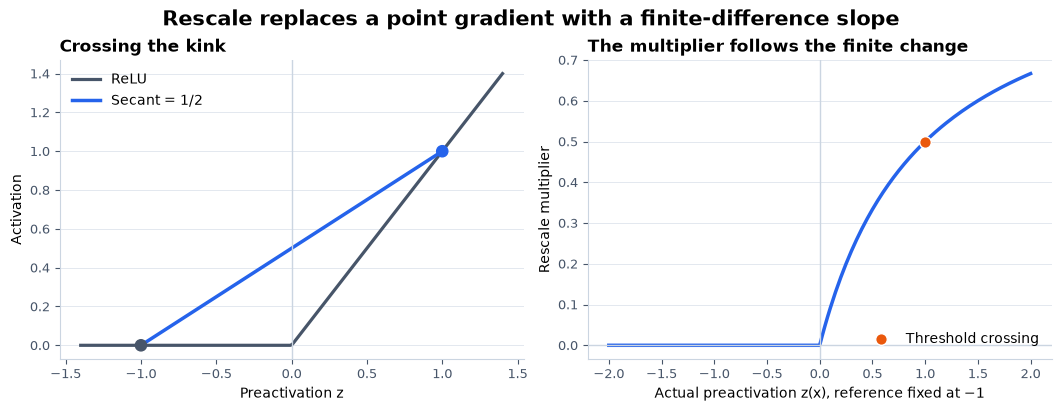

In [7]:
rescale_limits = diagnose_rescale_limits(globals())
show_figure(plots.plot_rescale_limits(rescale_limits), "01_rescale_limits")


## 3️⃣ Propagate modified multipliers

Ordinary backpropagation composes local derivatives. DeepLIFT instead starts from contributions
$C_{\Delta x_i\Delta t}$ and defines a multiplier

$$
m_{\Delta x_i\Delta t}=\frac{C_{\Delta x_i\Delta t}}{\Delta x_i}.
$$

For an intermediate layer $y_j$, the modified chain rule is

$$
m_{\Delta x_i\Delta t}=\sum_j
m_{\Delta x_i\Delta y_j}\,m_{\Delta y_j\Delta t}.
$$

An affine layer uses its weight matrix. A ReLU uses the secant you just implemented. Starting from
a unit output multiplier and traversing the modules in reverse therefore looks like backpropagation,
but every ReLU factor depends on the pair `(x,b)` rather than one derivative at `x`.

### Exercise 3 — `rescale_multipliers`

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 35-50 minutes on this exercise.
> ```

Return one output-to-input multiplier for every input/reference pair, shape `(N,B,D)`.


In [ ]:
def rescale_multipliers(model, x, background, epsilon=1e-6):
    """Backpropagate Rescale multipliers through a supported scalar Sequential model."""
    raise NotImplementedError()


tests.test_rescale_multipliers(rescale_multipliers)


<details><summary>Help - reverse the saved states</summary>

Call `paired_forward`. Initialize `multiplier` to ones with shape `(N,B,1)`. For layer index `i` in
reverse, an `nn.Linear` updates `multiplier @ layer.weight`. For an `nn.ReLU`, form its input pair
from `x_states[i][:,None,:]` and `b_states[i][None,:,:]`, then multiply by `rescale_slope`.

</details>

<details><summary>Expected output</summary>

```text
All tests in test_rescale_multipliers passed!
```

</details>

<details><summary>Interpretation</summary>

The output is not yet an attribution. It says how much output difference is assigned per unit input
difference for each pair. Exercise 4 multiplies it by the actual displacement `x-b`.

</details>

<details><summary>Solution</summary>

```python
@t.no_grad()
def rescale_multipliers(
    model: nn.Sequential,
    x: Tensor,
    background: Tensor,
    epsilon: float = 1e-6,
) -> Tensor:
    """Propagate scalar-output Rescale multipliers to every input feature."""
    layers = _layers(model)
    epsilon = _epsilon(epsilon)
    x_states, b_states = paired_forward(model, x, background)
    multiplier = t.ones((len(x), len(background), 1), dtype=t.float64)

    for index in range(len(layers) - 1, -1, -1):
        layer = layers[index]
        if type(layer) is nn.Linear:
            multiplier = t.einsum("nro,oi->nri", multiplier, layer.weight)
        else:
            slope = rescale_slope(
                x_states[index][:, None, :],
                b_states[index][None, :, :],
                epsilon,
            )
            multiplier = multiplier * slope
    return multiplier
```

</details>


## 4️⃣ Turn multipliers into single-reference contributions

For one reference $b$, Rescale contributions are

$$
\phi_i^{(b)}(x)=m_{\Delta x_i\Delta f}(x,b)(x_i-b_i).
$$

On a supported affine/ReLU chain with an exact secant at every changed ReLU, the modified chain rule
gives the summation-to-delta property

$$
\sum_i\phi_i^{(b)}(x)=f(x)-f(b).
$$

That identity is **local completeness**. The threshold example already proves that it does not imply
exact Shapley allocation over the original input features.

### Exercise 4 — `single_reference`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend up to 15-20 minutes on this exercise.
> ```

Accept a one-dimensional reference and return `(N,D)` contributions.


In [ ]:
def single_reference(model, x, reference, epsilon=1e-6):
    """Explain each row relative to one reference row."""
    raise NotImplementedError()


tests.test_single_reference(single_reference)


<details><summary>Help - keep the reference axis until the end</summary>

Convert the reference to shape `(1,D)`, call `rescale_multipliers`, select its length-one reference
axis, and multiply by `x - reference`.

</details>

<details><summary>Expected output</summary>

```text
All tests in test_single_reference passed!
```

The fixed threshold case must return `(2/3, 1/3)`, while an affine function
`2*x0 - 3*x1 + 5` at `x=(4,2)`, `b=(1,-1)` returns `(6,-9)`.

</details>

<details><summary>Interpretation</summary>

The affine case is exact because the same linear weights apply to every coalition and every
reference. The threshold network is complete but not exact for the feature game. Reporting these as
separate assertions prevents an easy but serious validation error.

</details>

<details><summary>Solution</summary>

```python
@t.no_grad()
def single_reference(
    model: nn.Sequential,
    x: Tensor,
    reference: Tensor,
    epsilon: float = 1e-6,
) -> Tensor:
    """Explain each query relative to one complete reference vector."""
    _method_tensor("x", x, 2)
    _method_tensor("reference", reference, 1)
    if x.shape[1] != reference.shape[0]:
        raise ValueError("reference must contain one value for every input feature.")
    multiplier = rescale_multipliers(model, x, reference[None, :], epsilon)[:, 0]
    return multiplier * (x - reference)
```

</details>


In [10]:
def near_zero_fixture():
    """Return the named ReLU crossing inside the 1e-6 fallback branch."""
    model = nn.Sequential(
        _linear([[1.0]], [0.0]),
        nn.ReLU(),
        _linear([[1.0]], [0.0]),
    ).eval()
    return {
        "model": model,
        "query": torch.tensor([[4e-7]], dtype=DTYPE),
        "reference": torch.tensor([-4e-7], dtype=DTYPE),
        "epsilon": 1e-6,
        "expected_primary_phi": torch.tensor([[0.0]], dtype=DTYPE),
        "expected_exact_secant_phi": torch.tensor([[4e-7]], dtype=DTYPE),
    }


In [11]:
def diagnose_near_zero(methods):
    """Expose the expected local-accuracy loss from the named epsilon branch."""
    single_reference = _method(methods, "single_reference")
    fixture = near_zero_fixture()
    model, query, reference = (
        fixture["model"],
        fixture["query"],
        fixture["reference"],
    )
    primary = single_reference(model, query, reference, epsilon=fixture["epsilon"])
    exact_secant = single_reference(model, query, reference, epsilon=0.0)
    prediction = _prediction(model, query)[0]
    base = _prediction(model, reference[None])[0]
    delta = prediction - base
    primary_residual = delta - primary.sum()
    exact_residual = delta - exact_secant.sum()
    return {
        "query": query,
        "reference": reference,
        "epsilon": fixture["epsilon"],
        "prediction": prediction,
        "base": base,
        "prediction_delta": delta,
        "primary_phi": primary,
        "exact_secant_phi": exact_secant,
        "expected_primary_phi": fixture["expected_primary_phi"],
        "expected_exact_secant_phi": fixture["expected_exact_secant_phi"],
        "primary_completeness_residual": primary_residual,
        "exact_secant_completeness_residual": exact_residual,
        "expected_primary_residual": torch.tensor(4e-7, dtype=DTYPE),
        "primary_phi_max_abs_error": _max_abs(primary, fixture["expected_primary_phi"]),
        "exact_secant_phi_max_abs_error": _max_abs(
            exact_secant, fixture["expected_exact_secant_phi"]
        ),
    }


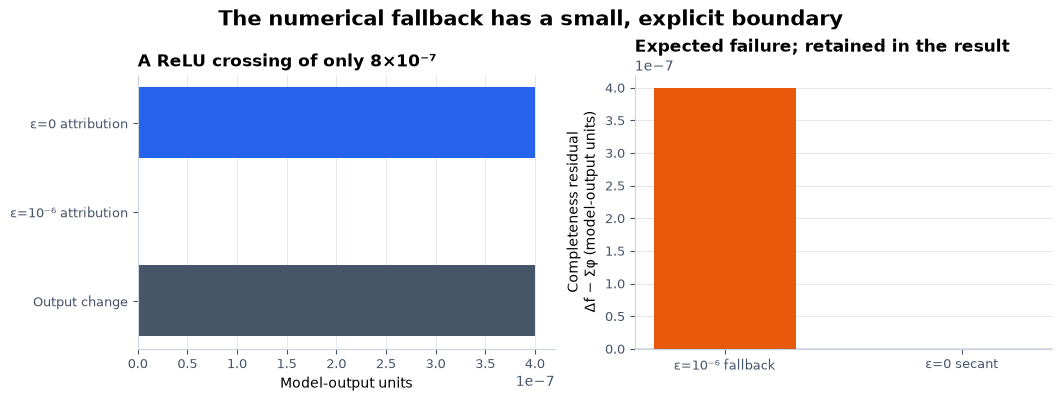

In [12]:
near_zero = diagnose_near_zero(globals())
show_figure(plots.plot_near_zero(near_zero), "02_near_zero_epsilon")


The near-zero panel is intentionally a failed case at the primary epsilon. Its residual is shown at
its true scale, beside the exact nonzero-secant result at `epsilon=0`.


In [13]:
def affine_fixture():
    """Return affine, dummy-input and constant controls with exact answers."""
    query = torch.tensor([[4.0, 2.0]], dtype=DTYPE)
    reference = torch.tensor([1.0, -1.0], dtype=DTYPE)
    affine = nn.Sequential(_linear([[2.0, -3.0]], [5.0])).eval()

    dummy_query = torch.tensor([[4.0, 2.0, 9.0]], dtype=DTYPE)
    dummy_reference = torch.tensor([1.0, -1.0, -4.0], dtype=DTYPE)
    dummy = nn.Sequential(_linear([[2.0, -3.0, 0.0]], [5.0])).eval()
    constant = nn.Sequential(_linear([[0.0, 0.0]], [7.0])).eval()
    return {
        "affine": {
            "model": affine,
            "query": query,
            "reference": reference,
            "expected_phi": torch.tensor([[6.0, -9.0]], dtype=DTYPE),
            "expected_base": torch.tensor(10.0, dtype=DTYPE),
            "expected_prediction": torch.tensor(7.0, dtype=DTYPE),
        },
        "dummy": {
            "model": dummy,
            "query": dummy_query,
            "reference": dummy_reference,
            "expected_phi": torch.tensor([[6.0, -9.0, 0.0]], dtype=DTYPE),
            "expected_base": torch.tensor(10.0, dtype=DTYPE),
            "expected_prediction": torch.tensor(7.0, dtype=DTYPE),
        },
        "constant": {
            "model": constant,
            "query": query,
            "reference": reference,
            "expected_phi": torch.zeros((1, 2), dtype=DTYPE),
            "expected_base": torch.tensor(7.0, dtype=DTYPE),
            "expected_prediction": torch.tensor(7.0, dtype=DTYPE),
        },
    }


In [14]:
def diagnose_affine_controls(methods):
    """Check exact affine credit, an unused input, and a constant network."""
    single_reference = _method(methods, "single_reference")
    answer = {}
    for name, fixture in affine_fixture().items():
        phi = single_reference(fixture["model"], fixture["query"], fixture["reference"])
        prediction = _prediction(fixture["model"], fixture["query"])[0]
        base = _prediction(fixture["model"], fixture["reference"][None])[0]
        answer[name] = {
            "query": fixture["query"],
            "reference": fixture["reference"],
            "phi": phi,
            "expected_phi": fixture["expected_phi"],
            "prediction": prediction,
            "expected_prediction": fixture["expected_prediction"],
            "base": base,
            "expected_base": fixture["expected_base"],
            "completeness_residual": prediction - base - phi.sum(),
            "phi_max_abs_error": _max_abs(phi, fixture["expected_phi"]),
        }
    answer["dummy_feature_max_abs"] = float(answer["dummy"]["phi"][0, 2].detach().abs())
    return answer


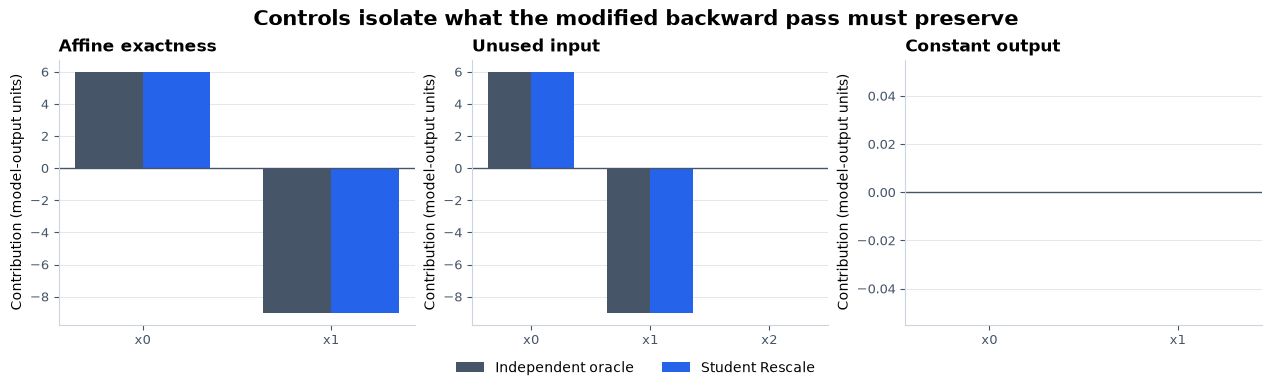

In [15]:
affine_controls = diagnose_affine_controls(globals())
show_figure(plots.plot_affine_controls(affine_controls), "03_affine_controls")


An affine network is the exactness control: modified multipliers, ordinary gradients and exact
Shapley must coincide, while a zero-weight dummy input must receive zero credit.


## 5️⃣ Average explanations over a background

A single reference makes the answer depend on one baseline. DeepSHAP uses a finite empirical
background $B$:

$$
\phi_i(x;B)=\frac1{|B|}\sum_{b\in B}\phi_i^{(b)}(x),\qquad
\phi_0(B)=\frac1{|B|}\sum_{b\in B}f(b).
$$

When the per-reference rule is complete,

$$
\phi_0(B)+\sum_i\phi_i(x;B)=f(x).
$$

The average is outside the attribution computation. In general,

$$
\frac1{|B|}\sum_b \phi(x;b) \ne \phi\!\left(x;\frac1{|B|}\sum_b b\right)
$$

because a mean reference can cross different ReLU regions and is not one of the intact donor rows.

### Exercise 5 — `background_deepshap`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 20-30 minutes on this exercise.
> ```

Return `(base, phi)`, where `base` is a scalar tensor and `phi` has shape `(N,D)`.


In [ ]:
def background_deepshap(model, x, background, epsilon=1e-6):
    """Average pairwise Rescale contributions over intact background rows."""
    raise NotImplementedError()


tests.test_background_deepshap(background_deepshap)


<details><summary>Help - average pairwise contributions</summary>

`rescale_multipliers` returns `(N,B,D)`. Multiply by
`x[:,None,:] - background[None,:,:]`, then average only dimension 1. Compute the base from
`model(background)`, not from `model(background.mean(0))`.

</details>

<details><summary>Common bug - explaining the mean reference</summary>

Replacing the whole background by its mean is valid only for special models such as an affine map.
For a nonlinear network it changes the reference game. Preserve every donor through the forward and
modified backward passes, then average the resulting attribution vectors.

</details>

<details><summary>Expected output</summary>

```text
All tests in test_background_deepshap passed!
```

For one-dimensional `ReLU(x)`, `x=2` and background `{-2,1}`, the base is `0.5` and the averaged
attribution is `1.5`. Explaining from the mean reference `-0.5` would instead return `2.0` around a
base of zero.

</details>

<details><summary>Interpretation</summary>

Reversing the rows of a fixed background cannot change the result. Changing which rows are in the
background can change both the base and the contributions; that is a change in the question, not
randomness inside this deterministic implementation.

</details>

<details><summary>Solution</summary>

```python
@t.no_grad()
def background_deepshap(
    model: nn.Sequential,
    x: Tensor,
    background: Tensor,
    epsilon: float = 1e-6,
) -> tuple[Tensor, Tensor]:
    """Average complete reference explanations and return E[f(background)]."""
    multiplier = rescale_multipliers(model, x, background, epsilon)
    pair_values = multiplier * (x[:, None, :] - background[None, :, :])
    with t.no_grad():
        base = _model_output(model, background).mean()
    return base, pair_values.mean(dim=1)
```

</details>


In [17]:
def background_average_fixture():
    """Return a nonlinear case where averaging references and inputs differ."""
    fixture = near_zero_fixture()
    fixture.update(
        {
            "query": torch.tensor([[2.0]], dtype=DTYPE),
            "background": torch.tensor([[-2.0], [1.0]], dtype=DTYPE),
            "expected_pair_phi": torch.tensor([[2.0], [1.0]], dtype=DTYPE),
            "expected_mean_phi": torch.tensor([[1.5]], dtype=DTYPE),
            "expected_base": torch.tensor(0.5, dtype=DTYPE),
            "expected_mean_reference_phi": torch.tensor([[2.0]], dtype=DTYPE),
            "expected_mean_reference_base": torch.tensor(0.0, dtype=DTYPE),
        }
    )
    fixture.pop("reference")
    fixture.pop("epsilon")
    fixture.pop("expected_primary_phi")
    fixture.pop("expected_exact_secant_phi")
    return fixture


In [18]:
def diagnose_background_average(methods):
    """Compare averaging attributions with explaining the mean reference."""
    single_reference = _method(methods, "single_reference")
    background_deepshap = _method(methods, "background_deepshap")
    fixture = background_average_fixture()
    model, query, background = fixture["model"], fixture["query"], fixture["background"]
    base, phi = background_deepshap(model, query, background)
    pair_phi = torch.stack(
        [single_reference(model, query, reference) for reference in background], dim=1
    ).squeeze(0)
    mean_reference = background.mean(dim=0)
    mean_reference_phi = single_reference(model, query, mean_reference)
    mean_reference_base = _prediction(model, mean_reference[None])[0]
    prediction = _prediction(model, query)[0]
    return {
        "query": query,
        "background": background,
        "mean_reference": mean_reference,
        "pair_phi": pair_phi,
        "expected_pair_phi": fixture["expected_pair_phi"],
        "phi": phi,
        "expected_phi": fixture["expected_mean_phi"],
        "base": base,
        "expected_base": fixture["expected_base"],
        "mean_reference_phi": mean_reference_phi,
        "expected_mean_reference_phi": fixture["expected_mean_reference_phi"],
        "mean_reference_base": mean_reference_base,
        "expected_mean_reference_base": fixture["expected_mean_reference_base"],
        "prediction": prediction,
        "averaging_gap": mean_reference_phi - phi,
        "phi_max_abs_error": _max_abs(phi, fixture["expected_mean_phi"]),
        "pair_phi_max_abs_error": _max_abs(pair_phi, fixture["expected_pair_phi"]),
    }


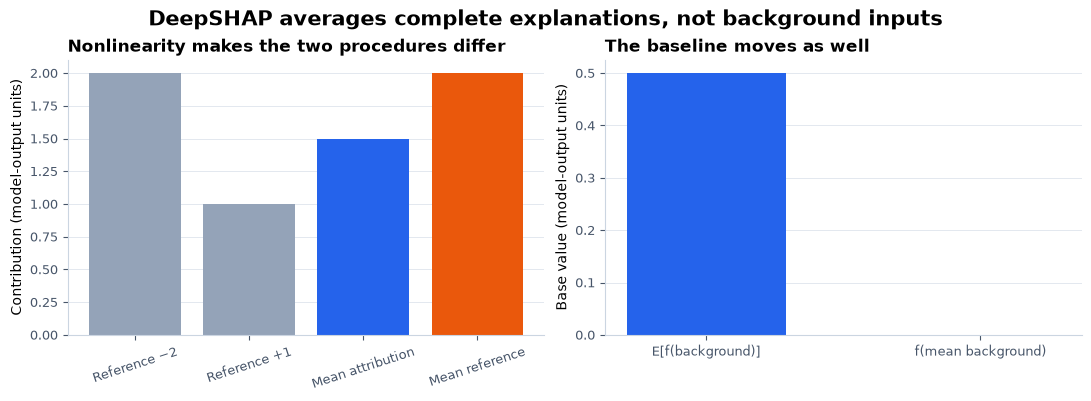

In [19]:
background_average = diagnose_background_average(globals())
show_figure(plots.plot_background_average(background_average), "04_background_average")


The control compares the correct average of pairwise explanations with the explanation relative to
the mean input. Their difference is visible precisely when the network is nonlinear across those
reference regions.


## 6️⃣ Define the exact empirical replacement game

DeepSHAP is fast because it composes local rules. To measure the approximation, we need an oracle
for the same finite background. For coalition $S$ and intact donor row $b$, define the hybrid

$$
h_i(x,b,S)=
\begin{cases}
x_i & i\in S,\\
b_i & i\notin S,
\end{cases}
\qquad
v_x(S)=\frac1{|B|}\sum_{b\in B} f(h(x,b,S)).
$$

Keeping each donor intact preserves correlations *within* a background row. It does not estimate a
conditional distribution for missing features. With eight features, evaluating all $2^8=256$
coalitions is affordable and gives a direct oracle for this explicitly stated marginal game.


In [20]:
def coalition_masks(d: int) -> Tensor:
    """Return all Boolean coalitions in integer order, with feature zero as bit zero."""
    if type(d) is not int or d < 1:
        raise ValueError("d must be a positive integer.")
    subset = t.arange(2**d, dtype=t.int64)
    feature = t.arange(d, dtype=t.int64)
    return subset[:, None].bitwise_and(1 << feature).ne(0)


### Exercise 6 — `coalition_values`

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 35-50 minutes on this exercise.
> ```

Return `(N,K)` coalition values for masks `(K,D)`. Batch both source rows and flattened model
forwards. Never average donor inputs before the model call.


In [ ]:
def coalition_values(model, x, background, masks, row_batch=8, forward_batch=65536):
    """Evaluate every intact-donor hybrid and average predictions over donors."""
    raise NotImplementedError()


tests.test_coalition_values(coalition_values)


<details><summary>Help - four useful axes</summary>

For a row chunk, construct hybrids with shape `(rows,K,B,D)` using
`torch.where(masks[None,:,None,:], x_chunk[:,None,None,:], background[None,None,:,:])`.
Flatten only for model evaluation, restore the four logical axes, then average the donor axis.

</details>

<details><summary>Expected output</summary>

```text
All tests in test_coalition_values passed!
```

The empty coalition equals the mean background prediction; the full coalition equals `f(x)` for
every source row.

</details>

<details><summary>Interpretation</summary>

`model(background.mean(0))` and `mean(model(background))` generally differ. The same nonlinearity is
why averaging donor inputs before constructing hybrids would define a different game.

</details>

<details><summary>Solution</summary>

```python
def coalition_values(
    model: nn.Sequential,
    x: Tensor,
    background: Tensor,
    masks: Tensor,
    row_batch: int = 8,
    forward_batch: int = 65_536,
) -> Tensor:
    """Evaluate every supplied intact-donor hybrid, then average over donors."""
    layers = _layers(model)
    _method_tensor("x", x, 2)
    _method_tensor("background", background, 2)
    if x.shape[1] != background.shape[1]:
        raise ValueError("x and background must have the same feature dimension.")
    _check_widths(layers, x.shape[1])
    if type(masks) is not Tensor or masks.device.type != "cpu" or masks.dtype != t.bool:
        raise TypeError("masks must be a CPU Boolean tensor.")
    if masks.ndim != 2 or masks.shape[1] != x.shape[1] or len(masks) == 0:
        raise ValueError("masks must have shape (nonempty coalitions, input features).")
    for name, size in (("row_batch", row_batch), ("forward_batch", forward_batch)):
        if type(size) is not int or size < 1:
            raise ValueError(f"{name} must be a positive integer.")

    result = t.empty((len(x), len(masks)), dtype=t.float64)
    with t.no_grad():
        for start in range(0, len(x), row_batch):
            query = x[start : start + row_batch]
            hybrids = t.where(
                masks[None, :, None, :],
                query[:, None, None, :],
                background[None, None, :, :],
            )
            flat = hybrids.reshape(-1, x.shape[1])
            predictions = t.cat(
                [
                    _model_output(model, flat[i : i + forward_batch])
                    for i in range(0, len(flat), forward_batch)
                ]
            )
            result[start : start + len(query)] = predictions.reshape(
                len(query), len(masks), len(background)
            ).mean(dim=2)
    return result
```

</details>


## 7️⃣ Contract every coalition into exact Shapley values

For $D$ features and feature $i$, exact Shapley is

$$
\phi_i=\sum_{S\subseteq [D]\setminus\{i\}}
\frac{|S|!(D-|S|-1)!}{D!}\left[v(S\cup\{i\})-v(S)\right].
$$

This is exact for the table it receives. It does not make the donor-replacement game conditional or
causal; those are properties of how `coalition_values` defined $v$, not of this contraction.

### Exercise 7 — `exact_shapley`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 25-35 minutes on this exercise.
> ```

Accept any leading batch shape and require the last dimension to be a power of two in bit order.


In [ ]:
def exact_shapley(values):
    """Contract a complete bit-ordered coalition table along its last axis."""
    raise NotImplementedError()


tests.test_exact_shapley(exact_shapley)


<details><summary>Help - pair masks by setting one bit</summary>

Infer `d` from `K=values.shape[-1]`. For each feature `i`, visit only integer masks where bit `i` is
zero; its paired present mask is `mask | (1 << i)`. Use `mask.bit_count()` for coalition size.

</details>

<details><summary>Expected output</summary>

```text
All tests in test_exact_shapley passed!
```

The threshold table `(0,0,0,1)` contracts to `(0.5,0.5)`, and every result sums to
`v(full)-v(empty)`.

</details>

<details><summary>Interpretation</summary>

The threshold comparison is now like-for-like: DeepSHAP and exact Shapley use the same input,
reference, model and feature players. Their `1/6` coordinate difference is compositional
approximation error, not a background mismatch.

</details>

<details><summary>Solution</summary>

```python
def exact_shapley(values: Tensor) -> Tensor:
    """Contract a complete (..., 2**D) game with exact Shapley weights."""
    _method_tensor("values", values)
    if values.ndim < 1:
        raise ValueError("values must have a final coalition axis.")
    size = values.shape[-1]
    d = size.bit_length() - 1
    if d < 1 or size != 2**d:
        raise ValueError("The final values axis must contain all 2**D coalitions for D >= 1.")

    result = t.zeros((*values.shape[:-1], d), dtype=t.float64)
    subset_ids = t.arange(size, dtype=t.int64)
    for feature in range(d):
        absent = subset_ids[subset_ids.bitwise_and(1 << feature).eq(0)]
        weights = t.tensor(
            [1 / (d * math.comb(d - 1, int(subset).bit_count())) for subset in absent],
            dtype=t.float64,
        )
        marginal = values[..., absent | (1 << feature)] - values[..., absent]
        result[..., feature] = (marginal * weights).sum(dim=-1)
    return result
```

</details>


Before recomputing the threshold example, we need one ordinary-gradient baseline. We provide it
because it is a control rather than a DeepSHAP rule:

$$
\phi_i^{\text{grad-delta}}(x;B)
=\frac1{|B|}\sum_{b\in B}\frac{\partial f(x)}{\partial x_i}(x_i-b_i).
$$

It uses one endpoint gradient at `x`; it is not Expected Gradients or GradientSHAP. Its sum need
not reconstruct a nonlinear prediction difference.


In [23]:
def gradient_delta(model: nn.Sequential, x: Tensor, background: Tensor) -> Tensor:
    """Point gradient at x times x minus the mean background; not GradientSHAP."""
    layers = _layers(model)
    _method_tensor("x", x, 2)
    _method_tensor("background", background, 2)
    if x.shape[1] != background.shape[1]:
        raise ValueError("x and background must have the same feature dimension.")
    _check_widths(layers, x.shape[1])

    query = x.detach().clone().requires_grad_(True)
    with t.enable_grad():
        output = _model_output(model, query)
        gradient = t.autograd.grad(output.sum(), query)[0]
    if not t.isfinite(gradient).all():
        raise ValueError("The model produced a nonfinite input gradient.")
    return (gradient * (query - background.mean(dim=0))).detach()


In [24]:
tests.test_gradient_delta(gradient_delta)


All tests in test_gradient_delta passed!


<details><summary>Expected output</summary>

```text
All tests in test_gradient_delta passed!
```

</details>


In [25]:
def threshold_fixture(
    weights: Sequence[float] = (2.0, 1.0),
    bias: float = -2.0,
    query: Sequence[float] = (1.0, 1.0),
    reference: Sequence[float] = (0.0, 0.0),
):
    """Build ``ReLU(w @ x + bias)`` as a supported explicit Sequential."""
    weights = torch.as_tensor(weights, dtype=DTYPE).reshape(1, -1)
    query = torch.as_tensor(query, dtype=DTYPE).reshape(1, -1)
    reference = torch.as_tensor(reference, dtype=DTYPE).reshape(-1)
    if query.shape[1] != weights.shape[1] or reference.shape != query.shape[1:]:
        raise ValueError("weights, query and reference must have one common feature size.")
    model = nn.Sequential(
        _linear(weights, [bias]),
        nn.ReLU(),
        _linear([[1.0]], [0.0]),
    ).eval()
    return {"model": model, "query": query, "reference": reference}


In [26]:
def diagnose_threshold(methods):
    """Show that Rescale can be complete while differing from exact Shapley."""
    single_reference = _method(methods, "single_reference")
    coalition_values = _method(methods, "coalition_values")
    exact_shapley = _method(methods, "exact_shapley")
    gradient_delta = _method(methods, "gradient_delta")
    fixture = threshold_fixture()
    model, query, reference = (
        fixture["model"],
        fixture["query"],
        fixture["reference"],
    )
    masks = torch.tensor([[0, 0], [1, 0], [0, 1], [1, 1]], dtype=torch.bool)
    game = coalition_values(model, query, reference[None], masks)
    deep = single_reference(model, query, reference)
    exact = exact_shapley(game)
    gradient = gradient_delta(model, query, reference[None])
    prediction, base = game[0, -1], game[0, 0]
    expected_game = torch.tensor([[0.0, 0.0, 0.0, 1.0]], dtype=DTYPE)
    expected_exact = torch.tensor([[0.5, 0.5]], dtype=DTYPE)
    expected_deep = torch.tensor([[2.0 / 3.0, 1.0 / 3.0]], dtype=DTYPE)
    expected_gradient = torch.tensor([[2.0, 1.0]], dtype=DTYPE)
    full_minus_feature = torch.stack([prediction - game[0, 2], prediction - game[0, 1]])
    return {
        "query": query,
        "reference": reference,
        "masks": masks,
        "game": game,
        "expected_game": expected_game,
        "deep": deep,
        "expected_deep": expected_deep,
        "exact": exact,
        "expected_exact": expected_exact,
        "gradient": gradient,
        "expected_gradient": expected_gradient,
        "full_minus_feature": full_minus_feature,
        "expected_full_minus_feature": torch.ones(2, dtype=DTYPE),
        "prediction": prediction,
        "base": base,
        "prediction_delta": prediction - base,
        "deep_completeness_residual": prediction - base - deep.sum(),
        "exact_completeness_residual": prediction - base - exact.sum(),
        "gradient_completeness_residual": prediction - base - gradient.sum(),
        "deep_exact_max_abs_error": _max_abs(deep, exact),
        "fixture_max_abs_error": max(
            _max_abs(game, expected_game),
            _max_abs(deep, expected_deep),
            _max_abs(exact, expected_exact),
            _max_abs(gradient, expected_gradient),
        ),
    }


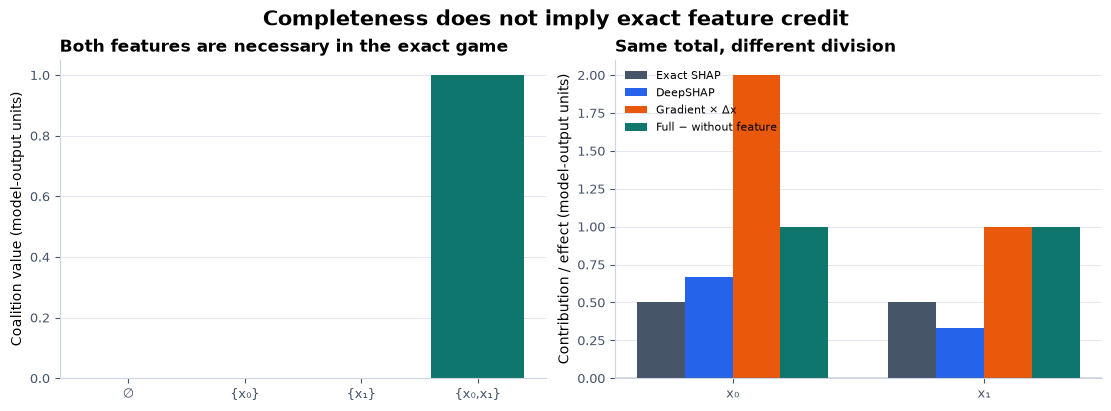

In [27]:
threshold = diagnose_threshold(globals())
show_figure(plots.plot_threshold(threshold), "05_threshold_complete_not_exact")


This is the cold-open result recomputed from your own methods. Exact and DeepSHAP share the same
endpoint and both satisfy completeness, but their individual feature bars disagree.


## 8️⃣ Diagnose cancellation with RevealCancel groups

Rescale treats a nonlinear unit as one secant from total reference preactivation to total actual
preactivation. Opposing incoming changes can cancel before that secant is assigned. DeepLIFT's
historical RevealCancel rule instead groups positive and negative changes and computes a two-player
Shapley allocation through one activation.

For reference preactivation $z_0$, positive group $p\ge0$, negative group $n\le0$ and activation
$g$:

$$
\begin{aligned}
C_p &= \tfrac12[g(z_0+p)-g(z_0)]
     + \tfrac12[g(z_0+n+p)-g(z_0+n)],\\
C_n &= \tfrac12[g(z_0+n)-g(z_0)]
     + \tfrac12[g(z_0+p+n)-g(z_0+p)].
\end{aligned}
$$

This bounded diagnostic is not called by our DeepSHAP core or by the current SHAP Rescale path.

### Exercise 8 — `reveal_cancel_groups`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵⚪⚪
>
> You should spend up to 20-30 minutes on this exercise.
> ```

Implement the two grouped allocations for a broadcast-compatible unary activation.


In [ ]:
def reveal_cancel_groups(activation, reference, positive, negative):
    """Return two-group Shapley allocations through one unary activation."""
    raise NotImplementedError()


tests.test_reveal_cancel_groups(reveal_cancel_groups)


<details><summary>Help - evaluate four activation states</summary>

You need `g(z0)`, `g(z0+p)`, `g(z0+n)` and `g(z0+p+n)`. Each group gets half its marginal when it
arrives first and half when it arrives second.

</details>

<details><summary>Expected output</summary>

```text
All tests in test_reveal_cancel_groups passed!
```

</details>

<details><summary>Interpretation</summary>

On nonnegative inputs, the network
`Linear([[0,1],[-1,1]]) -> ReLU -> Linear([[1,-1]])` computes
$x_1-\operatorname{ReLU}(x_1-x_0)=\min(x_0,x_1)$. At `x=(1,1)`, both inputs are necessary and exact
Shapley gives `(0.5,0.5)`, while Rescale assigns `(0,1)`. Mirroring the equivalent representation
assigns `(1,0)`. RevealCancel gives `(0.5,0.5)` in this grouped local diagnostic. The two networks
agree on all four binary inputs, so the difference exposes implementation dependence; neither
formula is claimed to represent `min` on arbitrary negative inputs.

</details>

<details><summary>Solution</summary>

```python
def reveal_cancel_groups(
    activation,
    reference: Tensor,
    positive: Tensor,
    negative: Tensor,
) -> tuple[Tensor, Tensor]:
    """Two-player Shapley allocation of positive/negative groups through one activation."""
    if not callable(activation):
        raise TypeError("activation must be callable.")
    for name, value in (("reference", reference), ("positive", positive), ("negative", negative)):
        _method_tensor(name, value)
    try:
        reference, positive, negative = t.broadcast_tensors(reference, positive, negative)
    except RuntimeError as error:
        raise ValueError(
            "reference, positive and negative must be broadcast-compatible."
        ) from error
    if (positive < 0).any() or (negative > 0).any():
        raise ValueError("positive must be nonnegative and negative must be nonpositive.")

    def activate(value: Tensor) -> Tensor:
        output = activation(value)
        if type(output) is not Tensor or output.shape != value.shape:
            raise TypeError("activation must return a tensor with the same shape as its input.")
        if output.device.type != "cpu" or output.dtype != t.float64 or not t.isfinite(output).all():
            raise ValueError("activation must return finite CPU float64 values.")
        return output

    base = activate(reference)
    positive_first = activate(reference + positive)
    negative_first = activate(reference + negative)
    together = activate(reference + positive + negative)
    positive_value = 0.5 * (positive_first - base + together - negative_first)
    negative_value = 0.5 * (negative_first - base + together - positive_first)
    return positive_value, negative_value
```

</details>


In [29]:
def min_fixture():
    """Return two graph forms of min(x0, x1) on nonnegative inputs."""
    first = nn.Sequential(
        _linear([[0.0, 1.0], [-1.0, 1.0]], [0.0, 0.0]),
        nn.ReLU(),
        _linear([[1.0, -1.0]], [0.0]),
    ).eval()
    mirrored = nn.Sequential(
        _linear([[1.0, 0.0], [1.0, -1.0]], [0.0, 0.0]),
        nn.ReLU(),
        _linear([[1.0, -1.0]], [0.0]),
    ).eval()
    return {
        "models": {"x1 route": first, "x0 route": mirrored},
        "query": torch.tensor([[1.0, 1.0]], dtype=DTYPE),
        "reference": torch.tensor([0.0, 0.0], dtype=DTYPE),
        "binary_inputs": torch.tensor(
            [[0.0, 0.0], [1.0, 0.0], [0.0, 1.0], [1.0, 1.0]], dtype=DTYPE
        ),
        "expected_binary": torch.tensor([0.0, 0.0, 0.0, 1.0], dtype=DTYPE),
        "expected_exact": torch.tensor([[0.5, 0.5]], dtype=DTYPE),
        "expected_deep": {
            "x1 route": torch.tensor([[0.0, 1.0]], dtype=DTYPE),
            "x0 route": torch.tensor([[1.0, 0.0]], dtype=DTYPE),
        },
    }


In [30]:
def diagnose_cancellation(methods):
    """Compare two equivalent min graphs and the bounded RevealCancel repair."""
    single_reference = _method(methods, "single_reference")
    coalition_values = _method(methods, "coalition_values")
    exact_shapley = _method(methods, "exact_shapley")
    reveal_cancel = _method(methods, "reveal_cancel_groups")
    fixture = min_fixture()
    query, reference = fixture["query"], fixture["reference"]
    masks = torch.tensor([[0, 0], [1, 0], [0, 1], [1, 1]], dtype=torch.bool)
    positive, negative = reveal_cancel(
        torch.relu,
        torch.tensor(0.0, dtype=DTYPE),
        torch.tensor(1.0, dtype=DTYPE),
        torch.tensor(-1.0, dtype=DTYPE),
    )
    reveal_phi = {
        "x1 route": torch.stack([-negative, 1.0 - positive])[None],
        "x0 route": torch.stack([1.0 - positive, -negative])[None],
    }
    models = {}
    for name, model in fixture["models"].items():
        game = coalition_values(model, query, reference[None], masks)
        deep = single_reference(model, query, reference)
        exact = exact_shapley(game)
        binary_prediction = _prediction(model, fixture["binary_inputs"])
        models[name] = {
            "binary_prediction": binary_prediction,
            "expected_binary": fixture["expected_binary"],
            "game": game,
            "deep": deep,
            "expected_deep": fixture["expected_deep"][name],
            "exact": exact,
            "expected_exact": fixture["expected_exact"],
            "reveal_cancel": reveal_phi[name],
            "binary_max_abs_error": _max_abs(binary_prediction, fixture["expected_binary"]),
            "deep_max_abs_error": _max_abs(deep, fixture["expected_deep"][name]),
            "exact_max_abs_error": _max_abs(exact, fixture["expected_exact"]),
            "reveal_cancel_max_abs_error": _max_abs(
                reveal_phi[name], fixture["expected_exact"]
            ),
        }
    return {
        "query": query,
        "reference": reference,
        "masks": masks,
        "models": models,
        "group_allocation": {"positive": positive, "negative": negative},
        "computational_domain": "nonnegative inputs",
        "deep_implementation_gap": models["x0 route"]["deep"] - models["x1 route"]["deep"],
    }


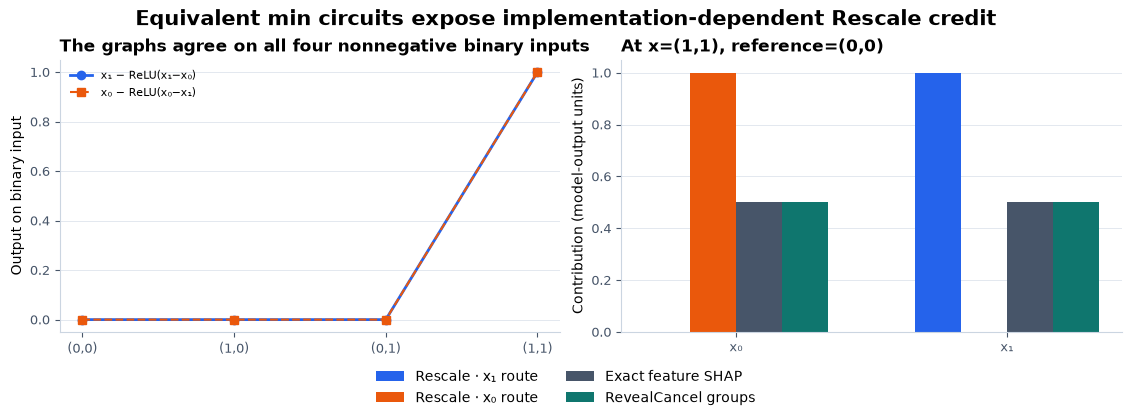

In [31]:
cancellation = diagnose_cancellation(globals())
show_figure(
    plots.plot_cancellation(cancellation),
    "06_cancellation_implementation_dependence",
)


The mirrored `min` implementations are a representation control. A feature attribution method that
follows hidden computational paths can change even when the tested input/output function does not.


## 9️⃣ Turn attribution rankings into intervention curves

Attribution agreement is one diagnostic. A second asks what the model does when features are
actually replaced. Rank features, then insert them into the empty coalition or delete them from the
full coalition. Because `values` already averages intact donor hybrids, every point can be looked up
without another model call.

For regressions whose full prediction lies below the empty value, reverse the attribution sign
before ranking so “largest first” means movement toward the full prediction. Treat an exactly zero
output difference as positive. Break ties by feature index so the result is reproducible.

### Exercise 9 — `ranked_replacement_curves`

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend up to 35-45 minutes on this exercise.
> ```

Return a dictionary with `orders`, integer `insertion_masks` and `deletion_masks`, plus the
corresponding raw prediction values. Optional supplied orders must contain an exact permutation on
every row.


In [ ]:
def ranked_replacement_curves(values, phi, orders=None):
    """Look up insertion and deletion prefixes in a complete coalition table."""
    raise NotImplementedError()


tests.test_ranked_replacement_curves(ranked_replacement_curves)


<details><summary>Help - build integer prefixes</summary>

For an order `(j0,...,jD-1)`, insertion indices are
`0, 2**j0, 2**j0+2**j1, ...`; deletion indices start at `2**D-1` and subtract the same bits. Gather
those indices along the coalition axis.

</details>

<details><summary>Common bug - assuming deletion is monotone</summary>

Feature replacement in an interacting model can make a prediction overshoot or reverse direction.
Preserve the raw MPa curve. Do not apply cumulative maxima, absolute values or smoothing to make it
look monotone.

</details>

<details><summary>Expected output</summary>

```text
All tests in test_ranked_replacement_curves passed!
```

Insertion begins at `v(empty)` and ends at `v(full)`; deletion visits the same endpoints in reverse.

</details>

<details><summary>Interpretation</summary>

A good ranking may move the prediction quickly, but this is not a proof that its attribution values
are exact. Compare DeepSHAP, exact Shapley, gradient-times-delta and 100 fixed random orders on the
same rows. Curves can overlap when methods happen to induce the same ranking.

</details>

<details><summary>Solution</summary>

```python
def ranked_replacement_curves(
    values: Tensor,
    phi: Tensor,
    orders: Tensor | None = None,
) -> dict[str, Tensor]:
    """Read insertion/deletion prefixes from a complete per-row coalition table."""
    _method_tensor("values", values, 2)
    _method_tensor("phi", phi, 2)
    n, size = values.shape
    d = size.bit_length() - 1
    if d < 1 or size != 2**d or phi.shape != (n, d):
        raise ValueError("values must be (N,2**D) and phi must be (N,D), with D >= 1.")

    if orders is None:
        direction = t.where(values[:, -1] - values[:, 0] >= 0, 1.0, -1.0)[:, None]
        orders = t.argsort(direction * phi, dim=1, descending=True, stable=True)
    else:
        if type(orders) is not Tensor or orders.device.type != "cpu" or orders.dtype != t.int64:
            raise TypeError("orders must be a CPU int64 tensor.")
        if orders.shape != (n, d):
            raise ValueError("orders must have shape (rows, features).")
        expected = t.arange(d, dtype=t.int64).expand(n, d)
        if not t.equal(orders.sort(dim=1).values, expected):
            raise ValueError("Every order row must contain each feature exactly once.")
        orders = orders.clone()

    insertion_masks = t.zeros((n, d + 1), dtype=t.int64)
    deletion_masks = t.full((n, d + 1), size - 1, dtype=t.int64)
    for step in range(d):
        bit = 1 << orders[:, step]
        insertion_masks[:, step + 1] = insertion_masks[:, step] | bit
        deletion_masks[:, step + 1] = deletion_masks[:, step] ^ bit
    return {
        "orders": orders,
        "insertion_masks": insertion_masks,
        "deletion_masks": deletion_masks,
        "insertion": values.gather(1, insertion_masks),
        "deletion": values.gather(1, deletion_masks),
    }
```

</details>


In [33]:
def replacement_fixture():
    """Return an additive three-player game with one exact dummy feature."""
    contributions = torch.tensor([3.0, -2.0, 0.0], dtype=DTYPE)
    masks = torch.tensor(
        [[bool(mask & (1 << feature)) for feature in range(3)] for mask in range(8)]
    )
    values = 10.0 + (masks.to(DTYPE) * contributions).sum(dim=1)
    return {
        "masks": masks,
        "values": values[None],
        "phi": contributions[None],
        "expected_order": torch.tensor([[0, 2, 1]], dtype=torch.long),
        "expected_insertion": torch.tensor([[10.0, 13.0, 13.0, 11.0]], dtype=DTYPE),
        "expected_deletion": torch.tensor([[11.0, 8.0, 8.0, 10.0]], dtype=DTYPE),
    }


In [34]:
def diagnose_replacement_control(methods):
    """Check ranked insertion/deletion endpoints and a zero-credit feature."""
    ranked_curves = _method(methods, "ranked_replacement_curves")
    fixture = replacement_fixture()
    result = ranked_curves(fixture["values"], fixture["phi"])
    return {
        **fixture,
        "result": result,
        "order_max_abs_error": _max_abs(result["orders"], fixture["expected_order"]),
        "insertion_max_abs_error": _max_abs(result["insertion"], fixture["expected_insertion"]),
        "deletion_max_abs_error": _max_abs(result["deletion"], fixture["expected_deletion"]),
        "dummy_insertion_change": result["insertion"][0, 2] - result["insertion"][0, 1],
        "dummy_deletion_change": result["deletion"][0, 2] - result["deletion"][0, 1],
    }


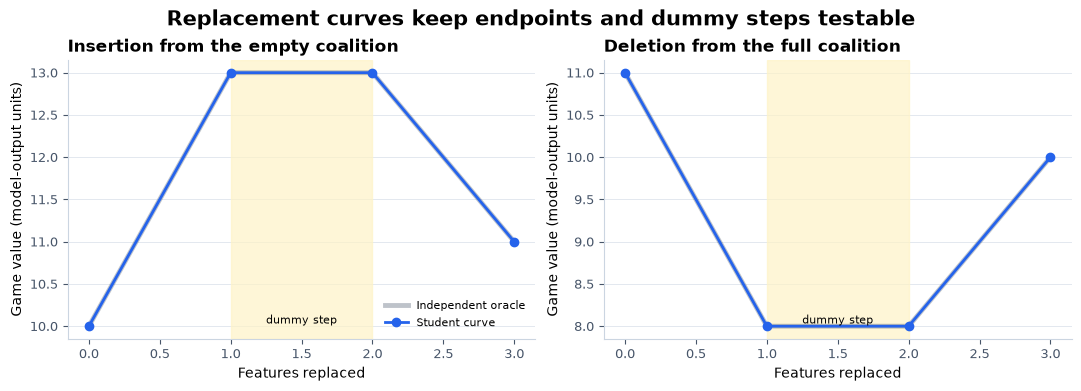

In [35]:
replacement_control = diagnose_replacement_control(globals())
show_figure(plots.plot_replacement_control(replacement_control), "07_replacement_fixture")


## From the modified backward pass to a real study

We now have three comparisons for the same model and finite background: the fast compositional
DeepSHAP approximation, exhaustive feature Shapley and the ordinary gradient-times-delta control.


In [36]:
methods = SimpleNamespace(
    paired_forward=paired_forward,
    rescale_slope=rescale_slope,
    rescale_multipliers=rescale_multipliers,
    single_reference=single_reference,
    background_deepshap=background_deepshap,
    coalition_values=coalition_values,
    exact_shapley=exact_shapley,
    reveal_cancel_groups=reveal_cancel_groups,
    ranked_replacement_curves=ranked_replacement_curves,
    coalition_masks=coalition_masks,
    gradient_delta=gradient_delta,
)


### Try It Yourself 1 — move the threshold

Edit the weights, bias, query, reference or epsilon. Look for regions where exact Shapley and
DeepSHAP agree, regions where both are complete but allocate differently, and the tiny interval
where the finite epsilon deliberately breaks completeness.


In [37]:
def threshold_play(
    methods,
    weights: Sequence[float] = (2.0, 1.0),
    bias: float = -2.0,
    query: Sequence[float] = (1.0, 1.0),
    reference: Sequence[float] = (0.0, 0.0),
    epsilon: float = 1e-6,
):
    """Recompute the editable gate with the learner's implemented methods."""
    single_reference = _method(methods, "single_reference")
    coalition_values = _method(methods, "coalition_values")
    exact_shapley = _method(methods, "exact_shapley")
    gradient_delta = _method(methods, "gradient_delta")
    fixture = threshold_fixture(weights, bias, query, reference)
    model, query_tensor, reference_tensor = (
        fixture["model"],
        fixture["query"],
        fixture["reference"],
    )
    dimension = query_tensor.shape[1]
    masks = torch.tensor(
        [
            [bool(mask & (1 << feature)) for feature in range(dimension)]
            for mask in range(2**dimension)
        ]
    )
    game = coalition_values(model, query_tensor, reference_tensor[None], masks)
    deep = single_reference(model, query_tensor, reference_tensor, epsilon=epsilon)
    exact = exact_shapley(game)
    gradient = gradient_delta(model, query_tensor, reference_tensor[None])
    return {
        "weights": torch.as_tensor(weights, dtype=DTYPE),
        "bias": float(bias),
        "query": query_tensor,
        "reference": reference_tensor,
        "epsilon": float(epsilon),
        "masks": masks,
        "game": game,
        "prediction": game[0, -1],
        "base": game[0, 0],
        "deep": deep,
        "exact": exact,
        "gradient": gradient,
        "deep_completeness_residual": game[0, -1] - game[0, 0] - deep.sum(),
        "deep_exact_max_abs_error": _max_abs(deep, exact),
    }


In [38]:
def run_diagnostics(methods=None, include_timing=True):
    """Collect every checkpoint after all nine methods have been defined.

    The lesson calls each diagnostic separately at its own checkpoint.  This
    convenience runner is reserved for the final native/reproduction harness,
    where the complete student-method namespace is already available.  There
    is no timing study in this section, so the separately persisted timing
    branch is intentionally empty.
    """

    def detach_tree(value):
        if isinstance(value, Tensor):
            return value.detach()
        if isinstance(value, dict):
            return {key: detach_tree(item) for key, item in value.items()}
        if isinstance(value, list):
            return [detach_tree(item) for item in value]
        if isinstance(value, tuple):
            return tuple(detach_tree(item) for item in value)
        return value

    mechanism = {
        "rescale_limits": diagnose_rescale_limits(methods),
        "near_zero": diagnose_near_zero(methods),
        "affine_controls": diagnose_affine_controls(methods),
        "background_average": diagnose_background_average(methods),
        "threshold": diagnose_threshold(methods),
        "cancellation": diagnose_cancellation(methods),
        "replacement_control": diagnose_replacement_control(methods),
        "threshold_play": threshold_play(methods),
    }
    return {"mechanism": detach_tree(mechanism), "timing": {} if include_timing else {}}


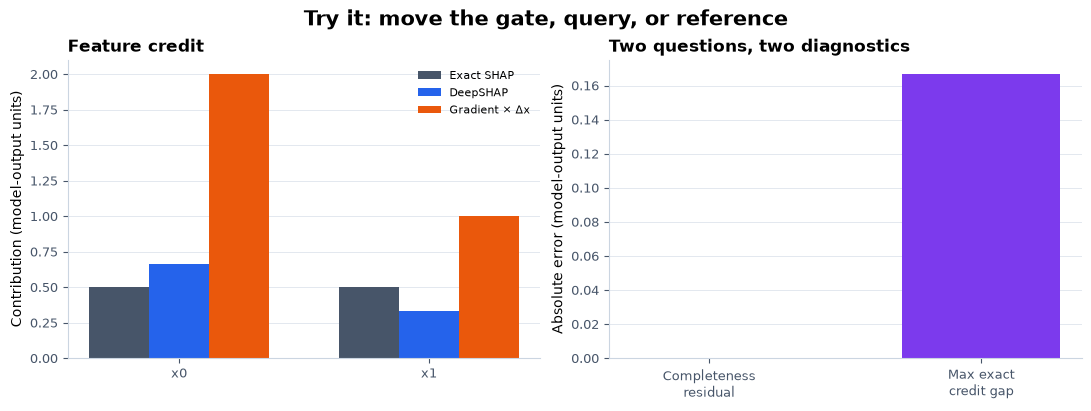

In [39]:
tiny_play = threshold_play(
    methods,
    weights=(2.0, 1.0),
    bias=-2.0,
    query=(1.0, 1.0),
    reference=(0.0, 0.0),
    epsilon=1e-6,
)
show_figure(plots.plot_threshold_play(tiny_play), "16_threshold_play")


<details><summary>Ideas to try</summary>

- Set both weights equal. Does symmetry force the two methods to agree?
- Move the bias until one feature can cross the threshold alone.
- Use `weights=(1,)`, `bias=0`, `query=(4e-7,)`, `reference=(-4e-7,)` and compare
  `epsilon=1e-6` with `epsilon=0`.
- Scale every weight and the bias by the same positive constant. Which quantities scale, and which
  ratios stay fixed?

</details>


## The frozen concrete-strength study

The data contain 1,030 public UCI concrete recipes with eight inputs and compressive strength in
MPa. Identical seven-ingredient recipes stay in the same split: 758 training rows, 153 explanation
rows and 119 audit rows. We train six fresh `8 -> 32 -> 32 -> 1` ReLU networks at three fixed seeds:
three with clean targets and three with independently shuffled targets. A ridge model is the affine
control. Every model operates in raw feature units after its training standardization is folded into
the first and last affine layers.

The shuffled networks and training-target mean test whether a visually detailed explanation can
make a poor predictor useful. The three clean seeds expose model variation; repeated agreement is
not treated as three independent uncertainty estimates. All seven models and all 272 held-out rows
remain in the results.

The fitting code is part of the lesson. It receives only the training split and retains its initial
state, standardized state, raw-unit state, loss trace, target permutation and training predictions.


In [40]:
from collections.abc import Mapping

from typing import Any

import numpy as np

import torch as t

from chapter16_shapley_attribution_baselines.exercises.part14_deepshap.deepshap_data import (
    background_order,
)

FEATURES = 8

HIDDEN = 32

TRAINING_STEPS = 800

LEARNING_RATE = 0.003

WEIGHT_DECAY = 0.0001

RIDGE_PENALTY = 0.01

MODEL_SEEDS = (161410, 161411, 161412)

SHUFFLE_SEEDS = (161420, 161421, 161422)

PRIMARY_BACKGROUND_SEED = 161460

INDEPENDENT_BACKGROUND_SEEDS = (161461, 161462)

RANDOM_ORDER_SEED = 161480


In [41]:
MODEL_KEYS = tuple(
    [f"clean_{index}" for index in range(3)]
    + [f"shuffled_{index}" for index in range(3)]
    + ["ridge"]
)

FEATURE_NAMES = (
    "Cement",
    "Slag",
    "Fly ash",
    "Water",
    "Superplasticizer",
    "Coarse aggregate",
    "Fine aggregate",
    "Age",
)

MODEL_LABELS = {
    **{f"clean_{index}": f"clean MLP seed {seed}" for index, seed in enumerate(MODEL_SEEDS)},
    **{
        f"shuffled_{index}": f"shuffled MLP seed {seed}"
        for index, seed in enumerate(MODEL_SEEDS)
    },
    "ridge": "ridge control",
}

METHOD_NAMES = (
    "rescale_multipliers",
    "background_deepshap",
    "coalition_values",
    "exact_shapley",
    "gradient_delta",
    "coalition_masks",
    "ranked_replacement_curves",
)

UNITS = {
    "input": "source feature units",
    "target": "MPa",
    "prediction": "MPa",
    "base": "MPa",
    "attribution": "MPa",
    "game": "MPa",
    "squared_error": "MPa squared",
}


In [42]:
from part14_deepshap.deepshap_study import (
    _clone_state,
    _clone_tree,
    _combine_explanations,
    _combine_row_blocks,
    _float_tensor,
    _ids_tensor,
    _normalization_tensors,
    _output_tensor,
    _require_disjoint_ids,
    _require_methods,
    _rows,
    _state_shapes,
    _validate_evaluation_inputs,
    _validate_fitted,
    _validate_rankings,
)


In [43]:
def _model_from_state(kind: str, state: Mapping[str, t.Tensor]) -> t.nn.Sequential:
    copied = _clone_state(state)
    shapes = _state_shapes(kind)
    if set(copied) != set(shapes):
        raise ValueError(f"{kind} state has unexpected parameter names.")
    if any(tuple(copied[name].shape) != shape for name, shape in shapes.items()):
        raise ValueError(f"{kind} state has an unexpected parameter shape.")
    if kind == "mlp":
        model = t.nn.Sequential(
            t.nn.Linear(FEATURES, HIDDEN, dtype=t.float64),
            t.nn.ReLU(),
            t.nn.Linear(HIDDEN, HIDDEN, dtype=t.float64),
            t.nn.ReLU(),
            t.nn.Linear(HIDDEN, 1, dtype=t.float64),
        )
    else:
        model = t.nn.Sequential(t.nn.Linear(FEATURES, 1, dtype=t.float64))
    model.load_state_dict(copied, strict=True)
    model.eval()
    return model

def make_model(item: Mapping[str, Any]) -> t.nn.Sequential:
    """Reconstruct a raw-input, raw-output Sequential solely from saved state."""
    if not isinstance(item, Mapping) or "kind" not in item or "state" not in item:
        raise TypeError("A fitted model item must contain kind and raw state.")
    return _model_from_state(str(item["kind"]), item["state"])


In [44]:
def _fold_mlp_state(
    standardized_state: Mapping[str, t.Tensor], normalization: Mapping[str, Any]
) -> dict[str, t.Tensor]:
    """Fold input and output standardization into the first and last affine layers."""
    state = _clone_state(standardized_state)
    if set(state) != set(_state_shapes("mlp")):
        raise ValueError("Cannot fold an unexpected MLP state.")
    x_mean, x_std, y_mean, y_std = _normalization_tensors(normalization)
    first_weight = state["0.weight"].clone()
    state["0.weight"] = first_weight / x_std[None, :]
    state["0.bias"] = state["0.bias"] - first_weight @ (x_mean / x_std)
    state["4.weight"] = y_std * state["4.weight"]
    state["4.bias"] = y_std * state["4.bias"] + y_mean
    return state

def _fold_ridge_state(
    standardized_state: Mapping[str, t.Tensor], normalization: Mapping[str, Any]
) -> dict[str, t.Tensor]:
    """Fold standardized linear regression back into raw feature and MPa units."""
    state = _clone_state(standardized_state)
    if set(state) != set(_state_shapes("ridge")):
        raise ValueError("Cannot fold an unexpected ridge state.")
    x_mean, x_std, y_mean, y_std = _normalization_tensors(normalization)
    weight = state["0.weight"].clone()
    state["0.weight"] = y_std * weight / x_std[None, :]
    state["0.bias"] = y_std * (
        state["0.bias"] - (weight * (x_mean / x_std)[None, :]).sum(1)
    ) + y_mean
    return state

def _folding_error(
    kind: str,
    standardized_state: Mapping[str, t.Tensor],
    raw_state: Mapping[str, t.Tensor],
    normalization: Mapping[str, Any],
    x_raw: t.Tensor,
) -> float:
    x_mean, x_std, y_mean, y_std = _normalization_tensors(normalization)
    standard_model = _model_from_state(kind, standardized_state)
    raw_model = _model_from_state(kind, raw_state)
    with t.no_grad():
        expected = standard_model((x_raw - x_mean) / x_std).squeeze(-1) * y_std + y_mean
        actual = raw_model(x_raw).squeeze(-1)
    return float((actual - expected).abs().max())


In [45]:
def _training_normalization(
    x_raw: t.Tensor, y_raw: t.Tensor
) -> tuple[dict[str, t.Tensor], t.Tensor, t.Tensor]:
    """Compute train-only moments and return standardized training coordinates."""
    normalization = {
        "x_mean": x_raw.mean(0),
        "x_std": x_raw.std(0, correction=0),
        "y_mean": y_raw.mean(),
        "y_std": y_raw.std(correction=0),
    }
    x_mean, x_std, y_mean, y_std = _normalization_tensors(normalization)
    x = (x_raw - x_mean) / x_std
    y = (y_raw - y_mean) / y_std
    return normalization, x, y


In [46]:
def _train_mlp(network: t.nn.Sequential, x: t.Tensor, labels: t.Tensor) -> t.Tensor:
    """Run the fixed full-batch Adam loop and retain every pre-update loss."""
    optimizer = t.optim.Adam(
        network.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    losses: list[t.Tensor] = []
    network.train()
    with t.enable_grad():
        for _ in range(TRAINING_STEPS):
            optimizer.zero_grad()
            loss = (network(x).squeeze(-1) - labels).square().mean()
            loss.backward()
            optimizer.step()
            losses.append(loss.detach().clone())
    return t.stack(losses)


In [47]:
def _fold_mlp_result(
    network: t.nn.Sequential,
    normalization: Mapping[str, Any],
    x_raw: t.Tensor,
) -> tuple[dict[str, t.Tensor], dict[str, t.Tensor], t.Tensor, float]:
    """Freeze both MLP coordinate systems and verify raw-unit prediction parity."""
    standardized_state = _clone_state(network.state_dict())
    raw_state = _fold_mlp_state(standardized_state, normalization)
    folding_error = _folding_error(
        "mlp", standardized_state, raw_state, normalization, x_raw
    )
    if folding_error > 1e-10:
        raise AssertionError("Raw-unit MLP folding changed its training predictions.")
    with t.no_grad():
        prediction = _model_from_state("mlp", raw_state)(x_raw).squeeze(-1)
    return standardized_state, raw_state, prediction, folding_error


In [48]:
def fit_one_mlp_control(
    control: str,
    index: int,
    x: t.Tensor,
    y: t.Tensor,
    x_raw: t.Tensor,
    y_raw: t.Tensor,
    normalization: Mapping[str, Any],
) -> dict[str, Any]:
    """Train one predeclared clean or label-shuffled MLP and fold it to raw units."""
    if control not in {"clean", "shuffled"} or index not in range(3):
        raise ValueError("Choose a clean or shuffled control and seed index 0, 1 or 2.")
    seed = MODEL_SEEDS[index]
    t.manual_seed(seed)
    network = t.nn.Sequential(
        t.nn.Linear(FEATURES, HIDDEN, dtype=t.float64),
        t.nn.ReLU(),
        t.nn.Linear(HIDDEN, HIDDEN, dtype=t.float64),
        t.nn.ReLU(),
        t.nn.Linear(HIDDEN, 1, dtype=t.float64),
    )
    initial_state = _clone_state(network.state_dict())
    permutation = t.arange(len(y), dtype=t.int64)
    shuffle_seed = None
    if control == "shuffled":
        shuffle_seed = SHUFFLE_SEEDS[index]
        permutation = t.from_numpy(
            np.random.default_rng(shuffle_seed).permutation(len(y))
        )
    labels = y[permutation]
    loss_trace = _train_mlp(network, x, labels)
    standardized_state, raw_state, prediction, folding_error = _fold_mlp_result(
        network, normalization, x_raw
    )
    return {
        "kind": "mlp",
        "control": control,
        "seed": seed,
        "initial_state": initial_state,
        "standardized_state": standardized_state,
        "state": raw_state,
        "loss_trace": loss_trace,
        "target_permutation": permutation.clone(),
        "training_targets_raw": y_raw[permutation].clone(),
        "training_prediction": prediction.clone(),
        "folding_max_abs_error": folding_error,
        "parameters": {
            "architecture": [FEATURES, HIDDEN, HIDDEN, 1],
            "steps": TRAINING_STEPS,
            "learning_rate": LEARNING_RATE,
            "weight_decay": WEIGHT_DECAY,
            "optimizer": "Adam",
            "risk": "mean_squared_error",
            "batch": "full_training_split",
            "shuffle_seed": shuffle_seed,
            "dtype": "float64",
            "parameter_count": sum(value.numel() for value in raw_state.values()),
        },
    }


In [49]:
def fit_ridge_control(
    x: t.Tensor,
    y: t.Tensor,
    x_raw: t.Tensor,
    y_raw: t.Tensor,
    normalization: Mapping[str, Any],
) -> dict[str, Any]:
    """Solve the fixed standardized ridge control once, excluding its intercept."""
    design = t.cat([x, t.ones((len(x), 1), dtype=t.float64)], dim=1)
    penalty = t.eye(FEATURES + 1, dtype=t.float64) * RIDGE_PENALTY
    penalty[-1, -1] = 0.0
    coefficients = t.linalg.solve(
        design.T @ design / len(x) + penalty,
        design.T @ y / len(x),
    )
    ridge_standardized_state = {
        "0.weight": coefficients[:FEATURES][None, :].clone(),
        "0.bias": coefficients[FEATURES:].clone(),
    }
    ridge_state = _fold_ridge_state(ridge_standardized_state, normalization)
    ridge_error = _folding_error(
        "ridge", ridge_standardized_state, ridge_state, normalization, x_raw
    )
    if ridge_error > 1e-10:
        raise AssertionError("Raw-unit ridge folding changed its training predictions.")
    with t.no_grad():
        ridge_prediction = _model_from_state("ridge", ridge_state)(x_raw).squeeze(-1)
    ridge_loss = (
        (_model_from_state("ridge", ridge_standardized_state)(x).squeeze(-1) - y)
        .square()
        .mean()
        .detach()
    )
    return {
        "kind": "ridge",
        "control": "ridge",
        "seed": 0,
        "initial_state": {},
        "standardized_state": _clone_state(ridge_standardized_state),
        "state": ridge_state,
        "loss_trace": ridge_loss[None].clone(),
        "target_permutation": t.arange(len(y_raw), dtype=t.int64),
        "training_targets_raw": y_raw.clone(),
        "training_prediction": ridge_prediction.clone(),
        "folding_max_abs_error": ridge_error,
        "parameters": {
            "penalty": RIDGE_PENALTY,
            "penalize_intercept": False,
            "risk": "mean_squared_error",
            "dtype": "float64",
            "parameter_count": FEATURES + 1,
        },
    }


In [50]:
def fit_models(train: Mapping[str, Any]) -> dict[str, Any]:
    """Fit six fixed MLPs and one ridge using training rows only."""
    x_raw, y_raw, train_ids = _rows(train, "train")
    t.set_num_threads(4)
    t.use_deterministic_algorithms(True)
    normalization, x, y = _training_normalization(x_raw, y_raw)
    models = {
        f"{control}_{index}": fit_one_mlp_control(
            control, index, x, y, x_raw, y_raw, normalization
        )
        for control in ("clean", "shuffled")
        for index in range(3)
    }
    models["ridge"] = fit_ridge_control(x, y, x_raw, y_raw, normalization)
    return {
        "models": models,
        "normalization": {name: value.detach().clone() for name, value in normalization.items()},
        "train_ids": train_ids,
        "train_x_raw": x_raw,
        "train_y_raw": y_raw,
        "units": dict(UNITS),
        "feature_names": FEATURE_NAMES,
        "model_labels": dict(MODEL_LABELS),
        "phase": "models_fitted_on_train_only",
    }


In [51]:
train = load_split("train")
explain = load_split("explain")
fitted = fit_models(train)


The primary background contains 64 training rows selected by a fixed source-ID hash, independent of
inputs, labels, predictions and attributions. The explanation split fixes feature rankings before
the audit labels are loaded. `explain_block` evaluates every model with the same student methods and
stores predictions, pairwise DeepSHAP values, the complete 256-coalition game, exact Shapley and the
ordinary gradient-times-delta baseline.


In [52]:
def _explain_model(
    item: Mapping[str, Any],
    x: t.Tensor,
    background: t.Tensor,
    methods: Any,
) -> dict[str, t.Tensor]:
    model = make_model(item)
    rows, donors = len(x), len(background)
    with t.no_grad():
        prediction = model(x).squeeze(-1)
        expected_base = model(background).squeeze(-1).mean()
    base, phi_deep = methods.background_deepshap(model, x, background)
    multipliers = methods.rescale_multipliers(model, x, background)
    pair_deep = multipliers * (x[:, None, :] - background[None, :, :])
    masks = methods.coalition_masks(FEATURES)
    game = methods.coalition_values(model, x, background, masks)
    phi_exact = methods.exact_shapley(game)
    phi_gradient = methods.gradient_delta(model, x, background)

    prediction = _output_tensor(prediction, (rows,), "prediction")
    base = _output_tensor(base, (), "base")
    phi_deep = _output_tensor(phi_deep, (rows, FEATURES), "phi_deep")
    pair_deep = _output_tensor(pair_deep, (rows, donors, FEATURES), "pair_deep")
    game = _output_tensor(game, (rows, 2**FEATURES), "game")
    phi_exact = _output_tensor(phi_exact, (rows, FEATURES), "phi_exact")
    phi_gradient = _output_tensor(phi_gradient, (rows, FEATURES), "phi_gradient")
    if not t.allclose(base, expected_base, atol=1e-10, rtol=1e-10):
        raise AssertionError("DeepSHAP base is not the mean background prediction.")
    if not t.allclose(phi_deep, pair_deep.mean(1), atol=1e-10, rtol=1e-10):
        raise AssertionError("DeepSHAP must average complete per-reference explanations.")
    if not t.allclose(game[:, 0], base.expand(rows), atol=1e-10, rtol=1e-10):
        raise AssertionError("The empty coalition does not equal the empirical background base.")
    if not t.allclose(game[:, -1], prediction, atol=1e-10, rtol=1e-10):
        raise AssertionError("The full coalition does not equal the raw model prediction.")
    return {
        "prediction": prediction,
        "base": base,
        "phi_deep": phi_deep,
        "phi_exact": phi_exact,
        "phi_gradient": phi_gradient,
        "game": game,
        "pair_deep": pair_deep,
    }

def explain_block(
    fitted: Mapping[str, Any],
    rows: Mapping[str, Any],
    background: Any,
    methods: Any,
) -> dict[str, dict[str, t.Tensor]]:
    """Explain every retained model on one named row block in raw units."""
    _validate_fitted(fitted)
    _require_methods(methods)
    x, _, _ = _rows(rows, "rows")
    background_tensor = _float_tensor(background, "background", 2)
    if background_tensor.shape[1:] != (FEATURES,) or len(background_tensor) == 0:
        raise ValueError("background must contain nonempty eight-feature donor rows.")
    return {
        key: _explain_model(fitted["models"][key], x, background_tensor, methods)
        for key in MODEL_KEYS
    }


In [53]:
def _background_indices(train_ids: t.Tensor) -> dict[str, t.Tensor]:
    primary = t.from_numpy(background_order(train_ids.numpy(), PRIMARY_BACKGROUND_SEED))
    independent_a = t.from_numpy(
        background_order(train_ids.numpy(), INDEPENDENT_BACKGROUND_SEEDS[0])
    )
    independent_b = t.from_numpy(
        background_order(train_ids.numpy(), INDEPENDENT_BACKGROUND_SEEDS[1])
    )
    if len(primary) < 128:
        raise ValueError("The frozen study requires at least 128 training donors.")
    return {
        "primary64": primary[:64].clone(),
        "nested16": primary[:16].clone(),
        "nested128": primary[:128].clone(),
        "independent64_a": independent_a[:64].clone(),
        "independent64_b": independent_b[:64].clone(),
    }


In [54]:
def prepare_study(
    fitted: Mapping[str, Any],
    train: Mapping[str, Any],
    explain: Mapping[str, Any],
    methods: Any,
) -> dict[str, Any]:
    """Explain and rank on the explanation split without receiving audit rows."""
    _validate_fitted(fitted)
    train_x, train_y, train_ids = _rows(train, "train")
    explain_x, explain_y, explain_ids = _rows(explain, "explain")
    _require_disjoint_ids(train=train_ids, explanation=explain_ids)
    if not t.equal(train_ids, fitted["train_ids"]):
        raise ValueError("Training identities changed after fitting.")
    if not t.equal(train_x, fitted["train_x_raw"]) or not t.equal(
        train_y, fitted["train_y_raw"]
    ):
        raise ValueError("Training values changed after fitting.")
    indices = _background_indices(train_ids)
    primary = train_x[indices["primary64"]]
    models = explain_block(fitted, explain, primary, methods)
    rankings = {
        key: {
            "exact": t.argsort(
                models[key]["phi_exact"].abs().mean(0), descending=True, stable=True
            ),
            "deep": t.argsort(models[key]["phi_deep"].abs().mean(0), descending=True, stable=True),
            "gradient": t.argsort(
                models[key]["phi_gradient"].abs().mean(0), descending=True, stable=True
            ),
        }
        for key in MODEL_KEYS
    }
    return {
        "models": models,
        "explain_ids": explain_ids,
        "explain_x_raw": explain_x,
        "explain_targets": explain_y,
        "background_ids": train_ids[indices["primary64"]],
        "background": primary,
        "background_indices": indices,
        "rankings": rankings,
        "audit_used_for_selection": False,
        "units": dict(UNITS),
        "feature_names": FEATURE_NAMES,
        "model_labels": dict(MODEL_LABELS),
        "phase": "rankings_frozen_before_audit",
    }


The next boundary is scientific, not cosmetic. `prepare_study` fixes the background and rankings
using train and explanation data. The executor persists both fitted and prepared payloads and their
hashes before the following literal audit load. No audit outcome can affect those choices.


In [55]:
from part14_deepshap.run_native import save_payload, write_before_audit

native_dir = Path(RUN_OUTPUT or section_dir / "native") / "native"
prepared = prepare_study(fitted, train, explain, methods)
save_payload(native_dir, "fitted.pt", fitted)
save_payload(native_dir, "prepared.pt", prepared)
write_before_audit(native_dir, prepared)


{'phase': 'prepared_before_audit',
 'audit_loaded': False,
 'fitted_sha256': '282fe37b7d332084db282afbd1707a827f06af176d6c814aa65329839ff5bddb',
 'prepared_sha256': 'b59ee37f6994e338f14df407c4c6103d290a0e06762b993641bbd554f217d29d',
 'explain_ids_sha256': '2687d4933988ba2da3867ac0f93702047d5f60ccc98c596c84f8ab6ddb756d10',
 'background_ids_sha256': '3639f7280290d3e1a008a891e6738a097a0971373c5bdcf475a3777dccc9996c'}

In [56]:
audit = load_split("audit")


Evaluation keeps the full audit arrays. The primary audit replacement experiment uses one global
mean-absolute feature ranking for each model and method, fixed on all 153 explanation rows and then
passed explicitly as the order for every audit row. It compares exact Shapley, DeepSHAP and
gradient-times-delta with 100 fixed random orders. Background variants use nested sizes 16, 64 and
128 plus independent 64-row draws, and recompute both the DeepSHAP approximation and exact game for
the primary clean model on all 272 held-out rows.


In [57]:
def _ranked_curves(
    game: t.Tensor, phi: t.Tensor, order: t.Tensor, methods: Any
) -> dict[str, t.Tensor]:
    expanded = order[None, :].expand(len(game), FEATURES).clone()
    curve = methods.ranked_replacement_curves(game, phi, expanded)
    expected = {
        "orders": (len(game), FEATURES),
        "insertion_masks": (len(game), FEATURES + 1),
        "deletion_masks": (len(game), FEATURES + 1),
        "insertion": (len(game), FEATURES + 1),
        "deletion": (len(game), FEATURES + 1),
    }
    if not isinstance(curve, Mapping) or set(curve) != set(expected):
        raise ValueError("Replacement curves returned an unexpected payload.")
    result: dict[str, t.Tensor] = {}
    for name, shape in expected.items():
        value = curve[name]
        if name.endswith("masks") or name == "orders":
            if not isinstance(value, t.Tensor) or value.dtype != t.int64:
                raise TypeError(f"{name} must be a long tensor.")
            if value.device.type != "cpu" or tuple(value.shape) != shape:
                raise ValueError(f"{name} has the wrong shape or device.")
            result[name] = value.detach().clone()
        else:
            result[name] = _output_tensor(value, shape, name)
    return result


In [58]:
def _random_curves(game: t.Tensor, orders: t.Tensor, methods: Any) -> dict[str, t.Tensor]:
    curves = [
        _ranked_curves(game, t.zeros((len(game), FEATURES), dtype=t.float64), order, methods)
        for order in orders
    ]
    return {
        "orders": orders.clone(),
        **{
            name: t.stack([curve[name] for curve in curves])
            for name in ("insertion_masks", "deletion_masks", "insertion", "deletion")
        },
    }


In [59]:
def _performance_table(
    fitted: Mapping[str, Any],
    models: Mapping[str, Mapping[str, t.Tensor]],
    audit_y: t.Tensor,
) -> dict[str, dict[str, Any]]:
    """Retain audit MSE for every model and the train-only mean baseline."""
    performance = {
        key: {
            "kind": fitted["models"][key]["kind"],
            "control": fitted["models"][key]["control"],
            "mse": (models[key]["prediction"] - audit_y).square().mean(),
        }
        for key in MODEL_KEYS
    }
    performance["training_mean"] = {
        "kind": "constant",
        "control": "training_mean",
        "mse": (audit_y - fitted["train_y_raw"].mean()).square().mean(),
    }
    return performance

def _fixed_random_orders() -> t.Tensor:
    """Draw the one frozen stream of 100 random feature-order controls."""
    rng = np.random.default_rng(RANDOM_ORDER_SEED)
    return t.from_numpy(np.stack([rng.permutation(FEATURES) for _ in range(100)]))


In [60]:
def _evaluate_replacements(
    models: Mapping[str, Mapping[str, t.Tensor]],
    rankings: Mapping[str, Mapping[str, t.Tensor]],
    random_orders: t.Tensor,
    methods: Any,
) -> dict[str, Any]:
    """Evaluate fixed global and random orders on every audit model and row."""
    replacement: dict[str, Any] = {}
    for key in MODEL_KEYS:
        replacement[key] = {
            name: _ranked_curves(
                models[key]["game"], models[key][f"phi_{name}"], rankings[key][name], methods
            )
            for name in ("exact", "deep", "gradient")
        }
        replacement[key]["random"] = _random_curves(
            models[key]["game"], random_orders, methods
        )
    return replacement


In [61]:
def _evaluate_background_variants(
    fitted: Mapping[str, Any],
    prepared: Mapping[str, Any],
    audit_models: Mapping[str, Mapping[str, t.Tensor]],
    rows: Mapping[str, t.Tensor],
    combined: Mapping[str, t.Tensor],
    methods: Any,
) -> dict[str, Any]:
    """Compare clean_0 on all held-out rows under five prespecified backgrounds."""
    primary = _combine_explanations(
        prepared["models"]["clean_0"], audit_models["clean_0"]
    )
    variants: dict[str, Any] = {
        "primary64": {
            **primary,
            "background": prepared["background"].clone(),
            "background_ids": prepared["background_ids"].clone(),
        }
    }
    for name in ("nested16", "nested128", "independent64_a", "independent64_b"):
        indices = prepared["background_indices"][name]
        background = rows["train_x"][indices]
        variants[name] = {
            **_explain_model(fitted["models"]["clean_0"], combined["x"], background, methods),
            "background": background.clone(),
            "background_ids": rows["train_ids"][indices].clone(),
        }
    for result in variants.values():
        result.update(
            row_ids=combined["ids"].clone(),
            row_split=combined["split"].clone(),
            targets=combined["y"].clone(),
        )
    return variants


In [62]:
def evaluate_study(
    fitted: Mapping[str, Any],
    prepared: Mapping[str, Any],
    train: Mapping[str, Any],
    explain: Mapping[str, Any],
    audit: Mapping[str, Any],
    methods: Any,
) -> dict[str, Any]:
    """Evaluate frozen rankings, controls and backgrounds on the audit split."""
    _require_methods(methods)
    rows = _validate_evaluation_inputs(fitted, prepared, train, explain, audit)
    models = explain_block(fitted, audit, prepared["background"], methods)
    performance = _performance_table(fitted, models, rows["audit_y"])
    random_orders = _fixed_random_orders()
    replacement = _evaluate_replacements(
        models, prepared["rankings"], random_orders, methods
    )
    combined = _combine_row_blocks(rows)
    background_variants = _evaluate_background_variants(
        fitted, prepared, models, rows, combined, methods
    )

    return {
        "models": models,
        "audit_ids": rows["audit_ids"],
        "audit_targets": rows["audit_y"],
        "performance": performance,
        "replacement_curves": replacement,
        "random_orders": random_orders,
        "background_variants": background_variants,
        "background_variant_order": (
            "primary64",
            "nested16",
            "nested128",
            "independent64_a",
            "independent64_b",
        ),
        "combined_explanation_audit_ids": combined["ids"],
        "combined_split": combined["split"],
        "combined_split_labels": ("explanation", "audit"),
        "model_order": MODEL_KEYS,
        "model_labels": dict(MODEL_LABELS),
        "feature_names": FEATURE_NAMES,
        "units": dict(UNITS),
        "audit_used_for_selection": False,
        "phase": "audit_evaluated_after_frozen_rankings",
    }


In [63]:
evaluated = evaluate_study(fitted, prepared, train, explain, audit, methods)


In [64]:
def native_play(
    fitted: Mapping[str, Any],
    train: Mapping[str, Any],
    audit: Mapping[str, Any],
    methods: Any,
    model_key: str = "clean_0",
    row: int = 0,
    size: int = 64,
) -> dict[str, Any]:
    """Recompute one audit recipe under an editable model and nested background."""
    _validate_fitted(fitted)
    _require_methods(methods)
    train_x, _, train_ids = _rows(train, "train")
    audit_x, audit_y, audit_ids = _rows(audit, "audit")
    if model_key not in MODEL_KEYS:
        raise ValueError("Choose one of the seven retained model keys.")
    if not 0 <= row < len(audit_x):
        raise ValueError("Choose an existing audit row.")
    if size not in (16, 64, 128):
        raise ValueError("Choose a nested background size of 16, 64 or 128.")
    order = t.from_numpy(background_order(train_ids.numpy(), PRIMARY_BACKGROUND_SEED))
    indices = order[:size]
    background = train_x[indices]
    x = audit_x[row : row + 1]
    result = _explain_model(fitted["models"][model_key], x, background, methods)
    curves = {
        name: _clone_tree(
            methods.ranked_replacement_curves(
                result["game"], result[f"phi_{name}"]
            )
        )
        for name in ("exact", "deep", "gradient")
    }
    return {
        "model_key": model_key,
        "source_id": int(audit_ids[row]),
        "query": x[0].clone(),
        "target": audit_y[row].clone(),
        "prediction": result["prediction"][0].clone(),
        "base": result["base"].clone(),
        "deep": result["phi_deep"][0].clone(),
        "exact": result["phi_exact"][0].clone(),
        "gradient": result["phi_gradient"][0].clone(),
        "game": result["game"][0].clone(),
        "pair_deep": result["pair_deep"][0].clone(),
        "curves": curves,
        "background_size": size,
        "background_ids": train_ids[indices].clone(),
        "background": background.clone(),
        "units": dict(UNITS),
        "feature_names": FEATURE_NAMES,
        "model_label": MODEL_LABELS[model_key],
        "audit_reuse": "exploratory",
    }


The independent reference reconstructs every saved raw-unit model without importing the student
methods. Installed `shap.DeepExplainer` checks all 15,232 averaged attribution coordinates. A more
expensive donor-level check covers the first explanation and first audit row for all seven models
and all 64 donors: 896 pair explanations and 7,168 coordinates. The exhaustive reference separately
checks every one of the 1,904 model-row games.


In [65]:
from part14_deepshap.deepshap_reference import validate_reference
from part14_deepshap.run_native import persist_completed, write_notebook_summary

reference = validate_reference(fitted, prepared, evaluated, train, explain, audit)
diagnostics = run_diagnostics(methods, include_timing=True)
fixed_play = native_play(fitted, train, audit, methods)
summary = persist_completed(
    native_dir,
    fitted,
    prepared,
    evaluated,
    diagnostics,
    reference,
    fixed_play,
)
write_notebook_summary(Path(RUN_OUTPUT or section_dir / "native"), native_dir, summary)

print("Independent DeepExplainer averaged-vector parity:", reference["status"])
print("Averaged coordinates checked:", reference["counts"]["author_attribution_coordinates"])
print("Bounded donor coordinates checked:", reference["counts"]["bounded_author_pair_coordinates"])
print("Exact game rows checked:", reference["counts"]["exact_game_model_rows"])


Independent DeepExplainer averaged-vector parity: PASS
Averaged coordinates checked: 15232
Bounded donor coordinates checked: 7168
Exact game rows checked: 1904


## Signature result: fast, complete, and measurably approximate

The first panel establishes that predictive skill belongs to the clean models rather than the
shuffled or mean controls. The next panels retain every signed feature value and every held-out row:
an identity-line scatter, row-by-feature error heatmaps, one predeclared-row waterfall, and a direct
three-method comparison. Do not replace these with only an aggregate error or a selected dramatic
example.

The frozen native study completed seven fresh fits in 8.01 seconds on the development CPU. Audit
mean-squared error was `31.04`, `35.61` and `36.58` MPa² for the three clean MLPs, compared with
`99.65` for ridge and `244.68` for the training-target mean. The shuffled-target controls were much
worse at `452.79`, `643.67` and `576.97` MPa². The explanation machinery can produce detailed
values for those controls, but it cannot turn them into useful predictors.

Across all 272 held-out rows, the three clean MLPs' mean absolute DeepSHAP-minus-exact coordinate
errors were `1.415`, `1.585` and `1.943` MPa; their largest coordinate errors were `10.87`, `17.75`
and `13.01` MPa. Yet their largest completeness residuals were only `4.97e-14`, `6.75e-14` and
`1.07e-13` MPa. Ridge is the decisive exactness control: its mean coordinate gap was `1.14e-15`
MPa. The installed DeepExplainer agreed with the student Rescale values to `1.71e-13` MPa, so the
neural gaps are approximation measurements rather than an implementation-parity failure.

The fixed source row 1 has target `61.89` MPa, prediction `70.6716` MPa and background base
`35.5483` MPa. Its exact versus DeepSHAP contributions differ visibly for coarse aggregate
(`3.3873` versus `6.9269` MPa), fine aggregate (`-2.4350` versus `-5.1074` MPa) and age (`2.9834`
versus `4.5909` MPa). This row was fixed before the audit was evaluated; it was not selected for a
large gap.


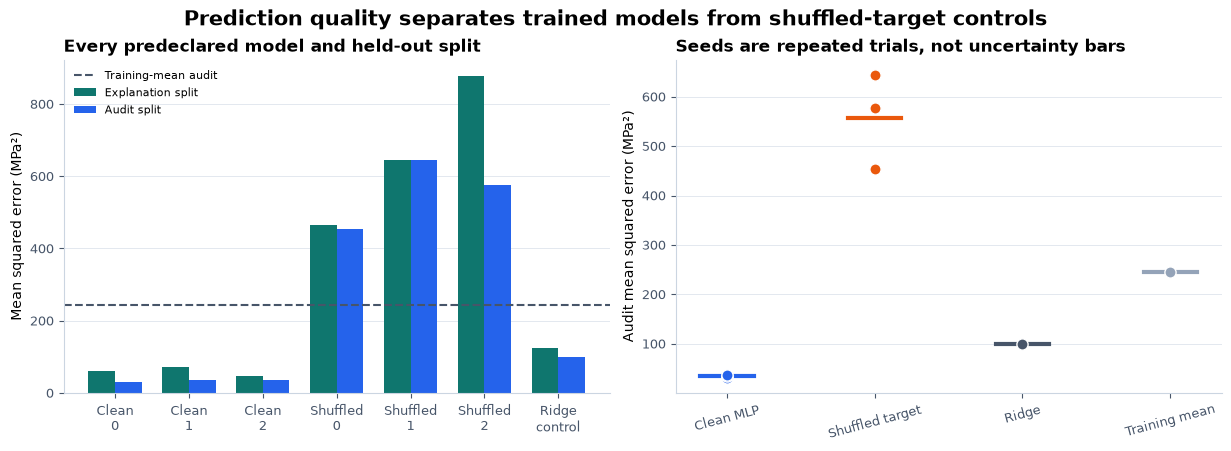

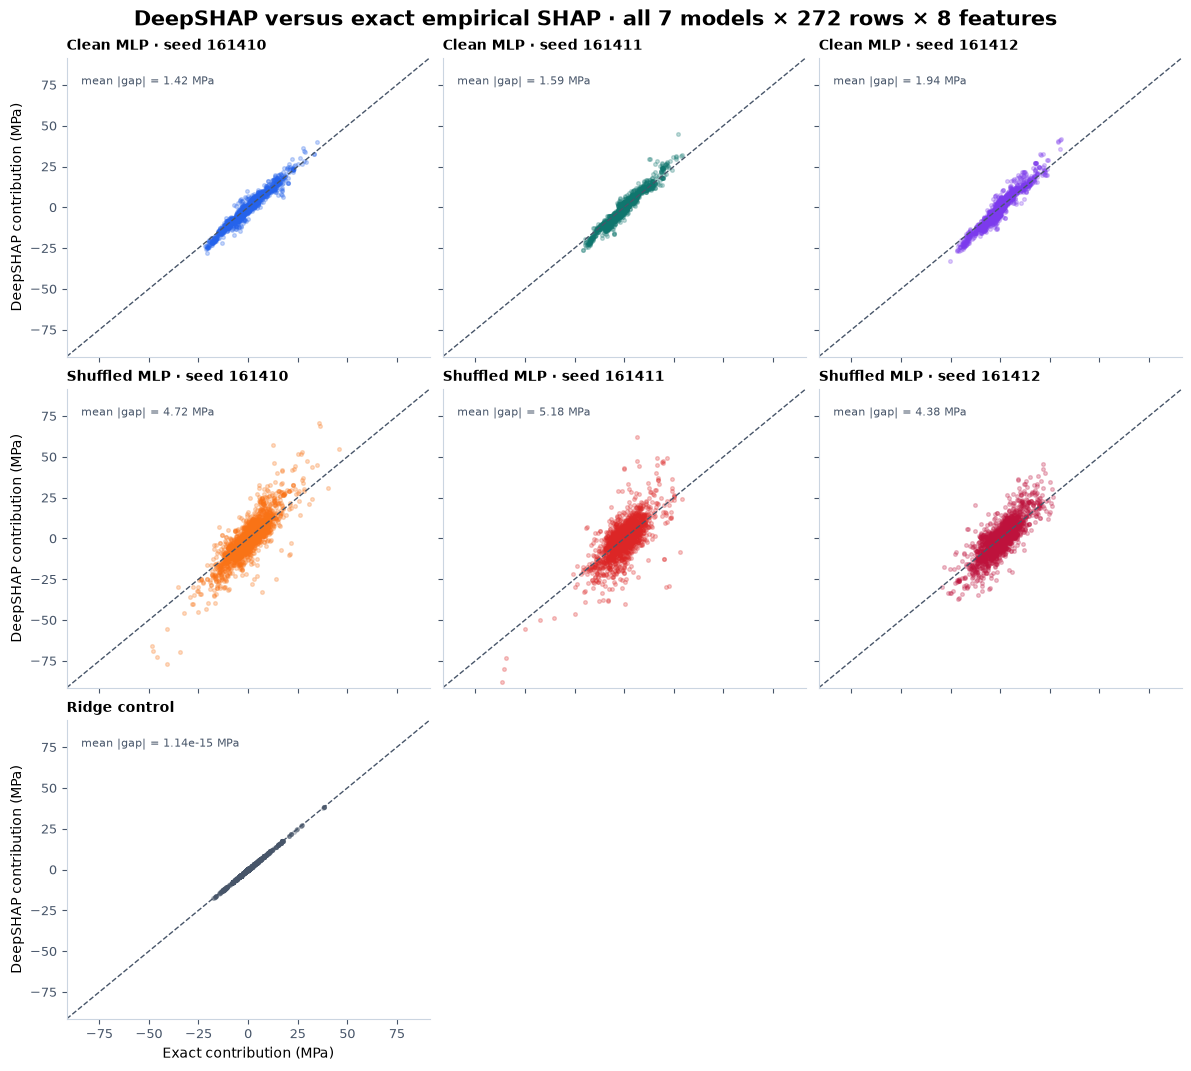

In [66]:
show_figure(plots.plot_performance(prepared, evaluated), "08_performance_controls")
show_figure(plots.plot_signed_parity(prepared, evaluated), "09_signed_parity_all_rows")


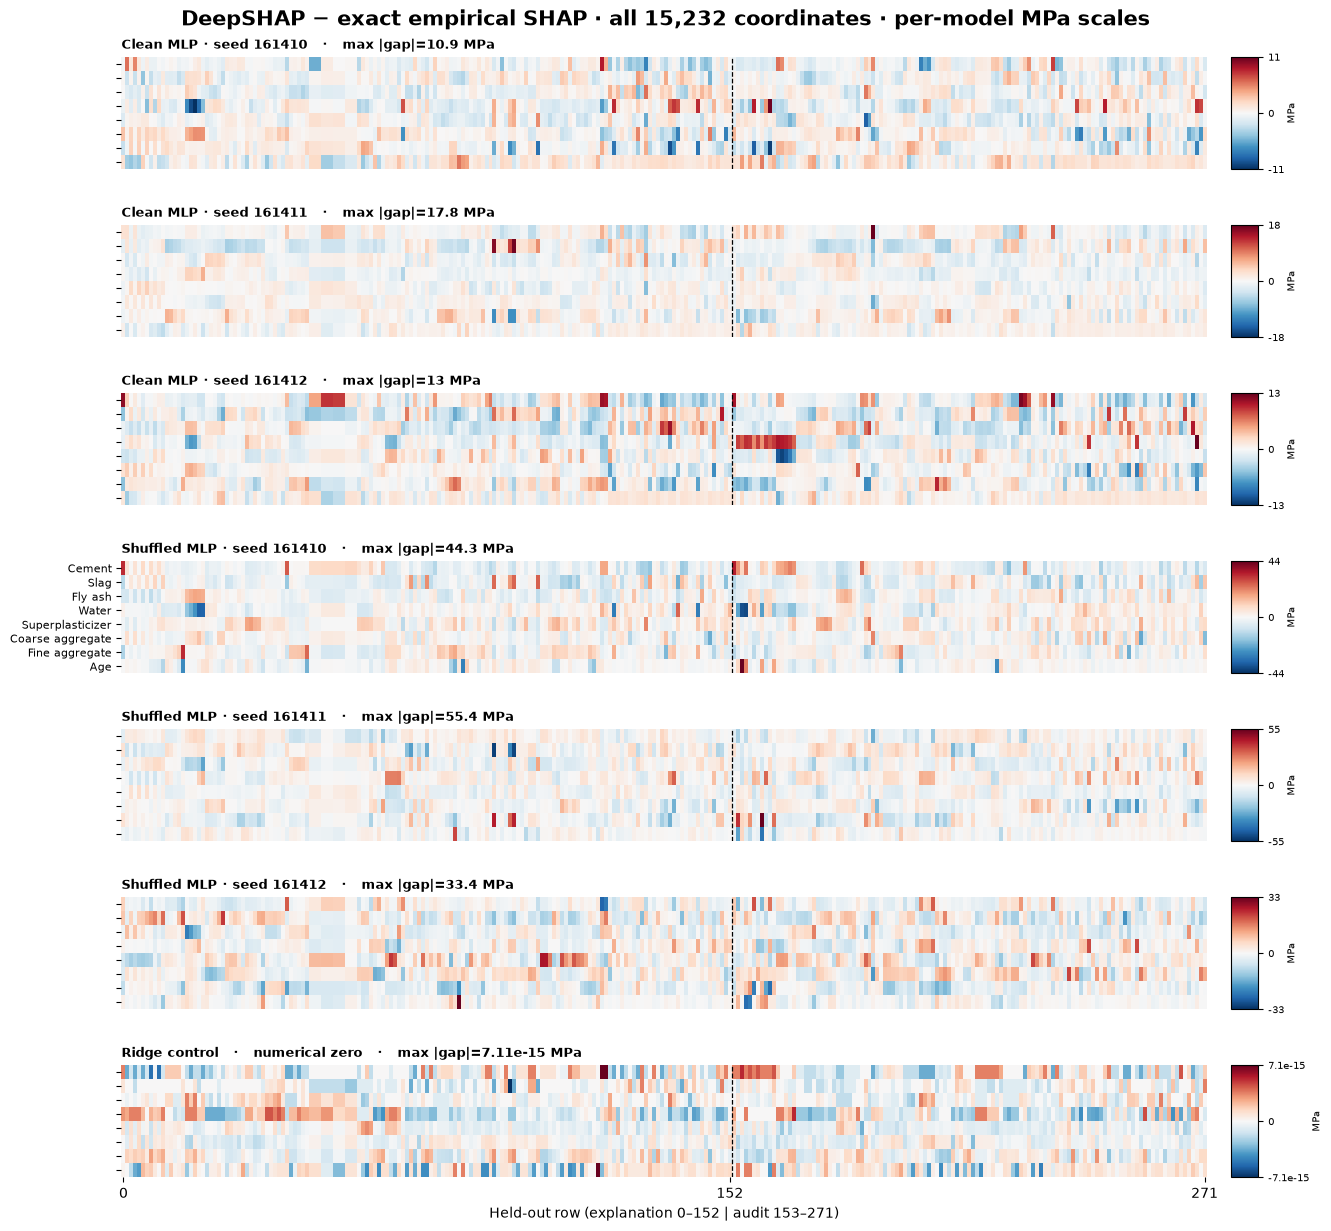

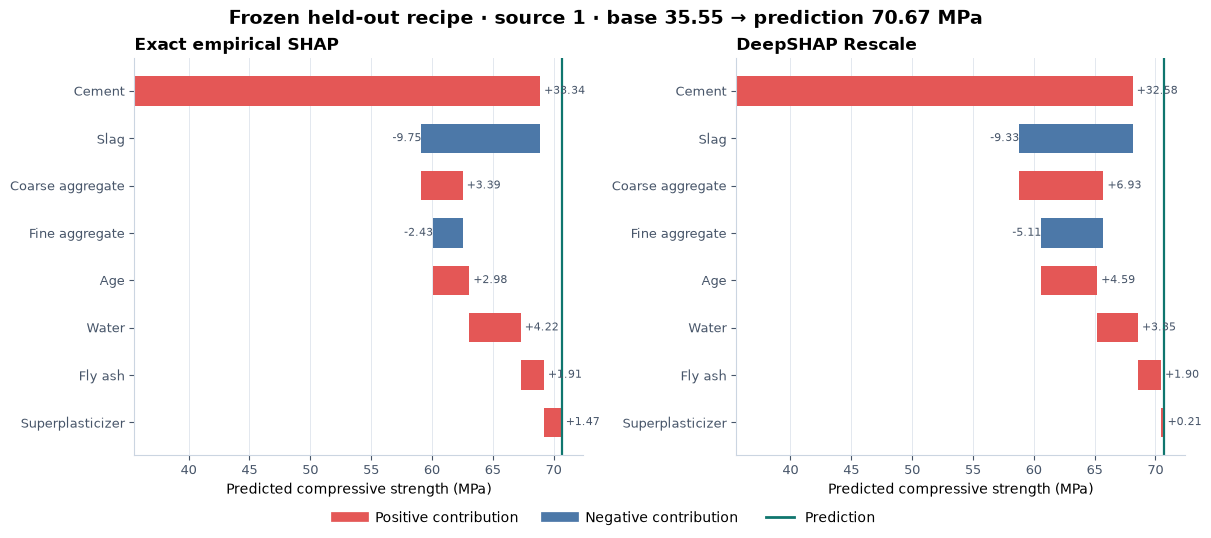

In [67]:
show_figure(plots.plot_error_heatmaps(prepared, evaluated), "10_error_heatmaps_all_rows")
show_figure(
    plots.plot_fixed_waterfall(fixed_play, feature_names=FEATURE_NAMES),
    "11_fixed_waterfall",
)


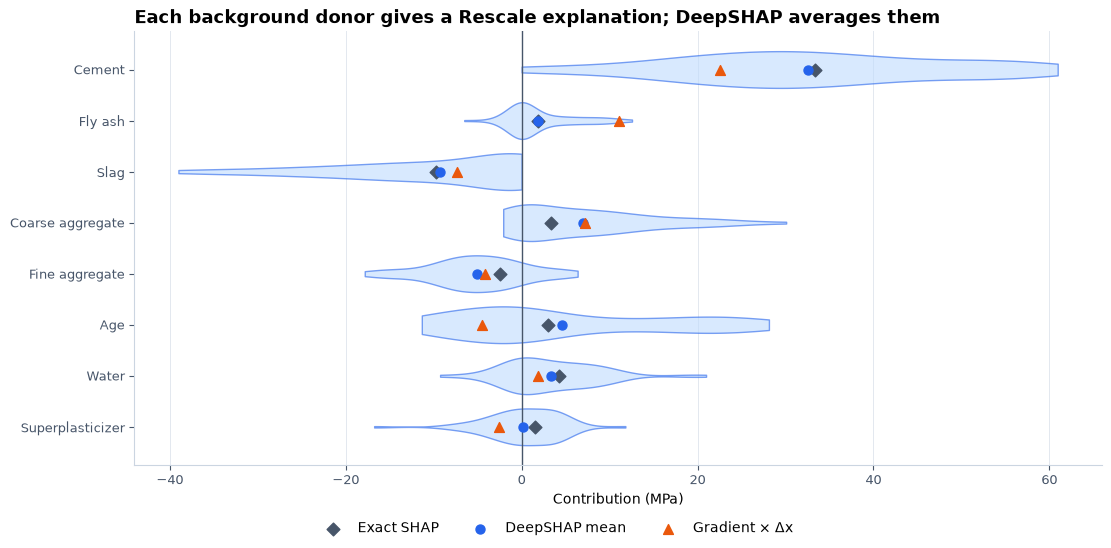

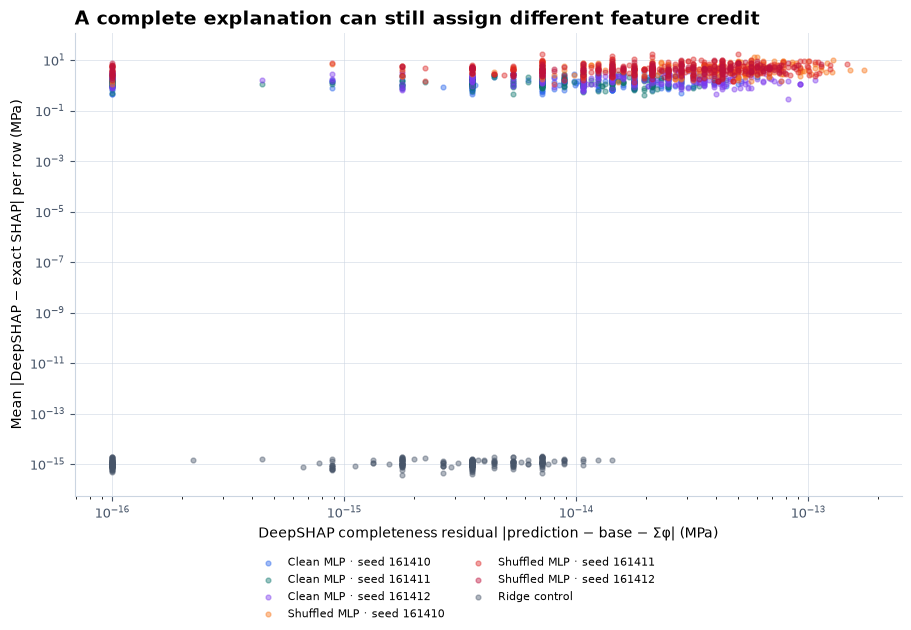

In [68]:
show_figure(
    plots.plot_fixed_attribution_comparison(fixed_play, feature_names=FEATURE_NAMES),
    "12_fixed_attribution_comparison",
)
show_figure(
    plots.plot_completeness_vs_exact(prepared, evaluated),
    "13_completeness_vs_exact",
)


### Three different questions about numerical validity

1. **Completeness:** does `base + phi.sum()` reproduce this model prediction? The finite-epsilon
   near-zero control records its known exception rather than hiding it in a loose tolerance.
2. **Independent implementation parity:** does the student Rescale method agree with installed
   `shap.DeepExplainer` on the explicitly supported affine/ReLU chain?
3. **Exact feature-game agreement:** does either implementation equal exhaustive Shapley for the
   same donor background and all 256 coalitions?

A method can pass the first two and fail the third. Independent-library agreement checks our
implementation of DeepSHAP; exhaustive agreement checks DeepSHAP as an approximation to this game.


## Background sensitivity and replacement controls

Changing a finite background changes both the base value and the game. The background panel shows
DeepSHAP movement beside exact-oracle movement, so sampling sensitivity is not mislabeled as
composition error. The replacement panel then compares ranked prefixes in raw MPa. Exact attribution
does not guarantee a monotone or uniformly superior prefix curve; these curves are model-behavior
diagnostics.

For the primary clean model, moving from the 64-row background to nested 16/128 backgrounds changed
exact coordinates by `0.784`/`0.593` MPa on average; the two independent 64-row backgrounds changed
them by `0.942`/`0.759` MPa. Their base predictions ranged from `32.581` to `38.012` MPa. These
finite-background movements are large enough to interpret alongside, rather than underneath, the
`1.278`–`1.531` MPa mean approximation gaps across the five background designs.

On the primary clean model, exact and DeepSHAP global orders agree that cement comes first but swap
slag and age next. DeepSHAP's first two insertions produced an average oriented gain of `11.319`
MPa, versus `5.796` MPa for the exact order; both orders were identical after the third feature and
ended at `12.022` MPa. This is a useful negative result: a better early replacement curve is not
evidence that an attribution vector is closer to exact Shapley.


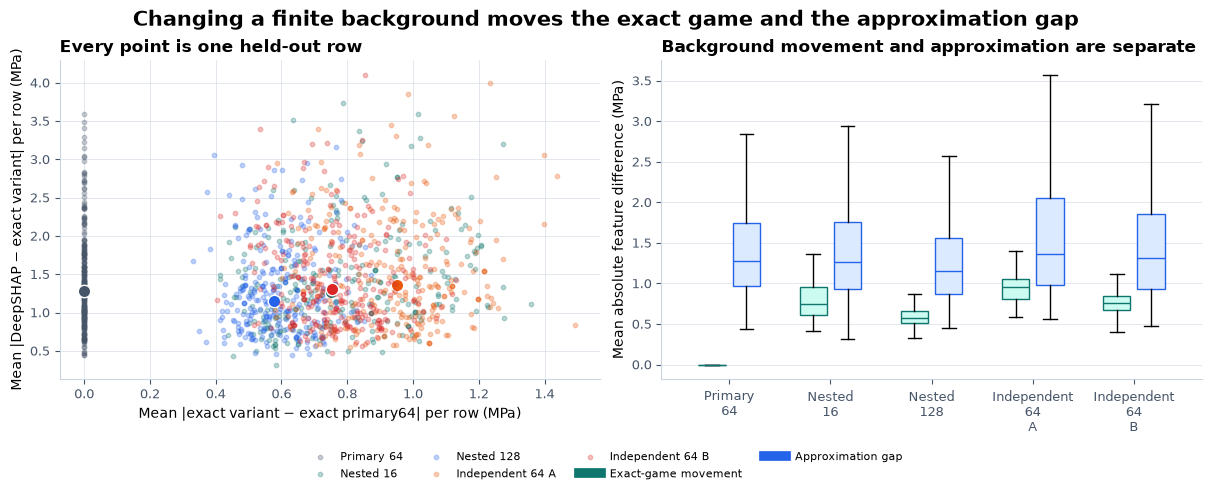

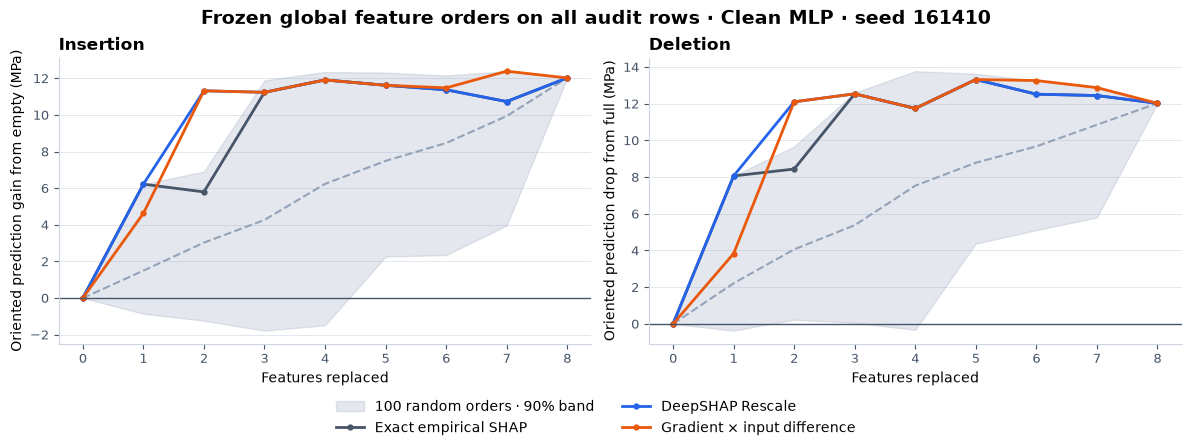

In [69]:
show_figure(plots.plot_background_sensitivity(evaluated), "14_background_sensitivity")
show_figure(plots.plot_replacement_curves(evaluated), "15_replacement_curves")


### Try It Yourself 2 — choose a recipe, model and background

The canonical first run uses `clean_0`, audit row 0 (source row 1) and the frozen 64-row background.
After reproducing that result, edit the arguments. The play recomputes the approximate explanation,
exact game and replacement curves rather than slicing a cached chart. Its curves use the local
per-row ordering from Exercise 9, oriented by `sign(f(x)-base)`. They are exploratory and distinct
from the primary experiment's frozen global explanation-split rankings.


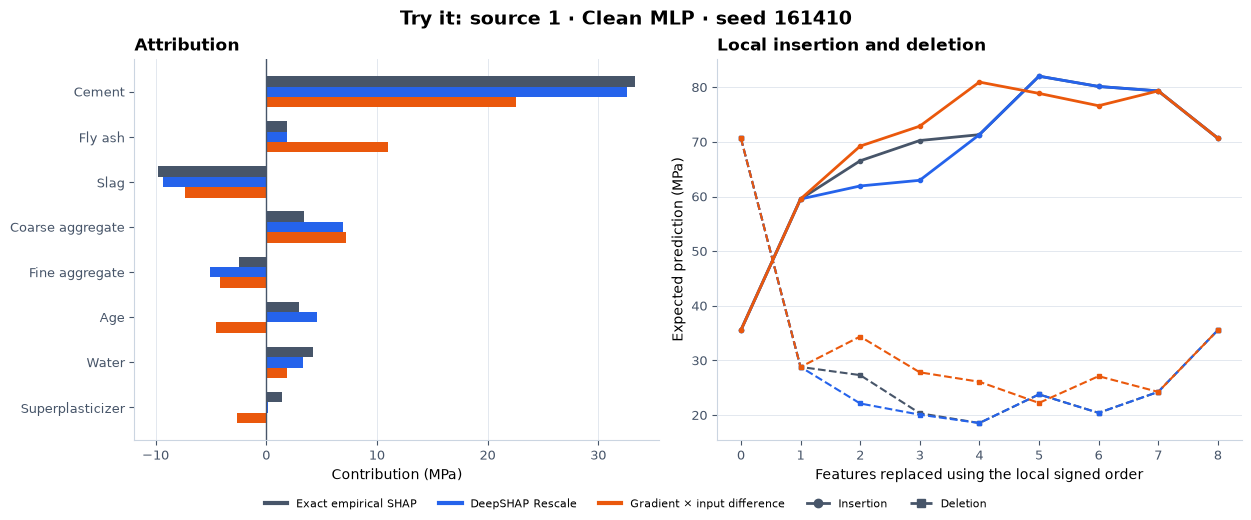

In [70]:
play = native_play(
    fitted,
    train,
    audit,
    methods,
    model_key="clean_0",
    row=0,
    size=64,
)
show_figure(
    plots.plot_real_recipe_play(play, feature_names=FEATURE_NAMES),
    "17_real_recipe_play",
)


<details><summary>Ideas to try</summary>

- Compare `clean_0`, `clean_1`, `clean_2`, `shuffled_0` and `ridge` on the same source row.
- Keep the model and row fixed while changing the nested background size from 16 to 64 to 128.
- Find a row where the DeepSHAP and exact rankings agree even though their signed magnitudes differ.
- Find an overshooting deletion curve and inspect which interaction makes a replacement reverse the
  expected direction.

These choices occur after audit evaluation. They are exploratory diagnostics and cannot support a
new confirmatory audit claim.

</details>


## How to interpret the study

Read the figures in this order:

1. Confirm that clean models beat the training-mean and shuffled-target controls. Attribution from
   a model without held-out predictive skill does not rescue the predictor.
2. Require exact endpoint identities and full-vector parity with the exhaustive oracle for the
   affine control. Then inspect independent DeepExplainer parity separately.
3. Check completeness and exact error side by side. Near-zero epsilon failure is a stated numerical
   rule; larger exact errors with small completeness residuals are approximation behavior.
4. Compare all-row signed errors before the fixed-row waterfall. A waterfall explains where one
   prediction came from; it does not establish a population pattern.
5. Read background movement beside exact movement, and replacement curves beside random-order
   bands. Do not infer a universal method ranking from one model or overlapping curves.

For the concrete data, replacing one recorded quantity while borrowing the others from observed
training recipes creates synthetic model inputs. These are computational interventions on the
network. They are not randomized experiments on concrete production, and the empirical background
is not evidence that the attributions are physical causal effects.

## Limitations and method scope

The student method covers scalar affine/ReLU `nn.Sequential` chains with distinct modules. It
rejects convolution, pooling, softmax, multiplication, residual branches, shared modules,
normalization layers and custom operators. Current DeepSHAP libraries use backend-specific rules for
some additional components, and unsupported behavior can vary by backend. Agreement here should not
be generalized to an arbitrary PyTorch graph.

DeepSHAP is deterministic for a fixed model, query, background and epsilon. It is an approximation
to exact feature Shapley for a composed nonlinear graph, even when its local sum is exact. Exact
enumeration scales as $2^D$ and is available here only because the study has eight inputs. A finite
background approximates a chosen reference distribution and can move the answer materially.

RevealCancel explains one historical response to cancellation. It is not part of the taught
DeepSHAP core or the installed library comparison. Gradient-times-delta is a deterministic baseline,
not GradientSHAP or Expected Gradients; those methods require their own sampling and path-integral
lesson.

## Further research and anomaly hunting

- Characterize which ReLU activation patterns make Rescale equal exact input-feature Shapley.
- Construct functionally equivalent networks with increasingly different DeepSHAP allocations.
- Locate the smallest background for which ranking and signed-value conclusions stabilize, while
  recomputing the exact oracle at every size.
- Extend the visible dispatcher by one operator and design an exact fixture that can falsify its
  rule before applying it to a real model.
- Compare the finite-epsilon fallback with a scale-aware alternative without choosing its threshold
  from audit errors.

## Reading

- Lundberg & Lee,
  [*A Unified Approach to Interpreting Model Predictions*](https://arxiv.org/abs/1705.07874),
  especially the Deep SHAP discussion and compositional approximation.
- Shrikumar, Greenside & Kundaje, [*Learning Important Features Through Propagating Activation
  Differences*](https://arxiv.org/abs/1704.02685), plus its supplement for Rescale and RevealCancel.
- The current SHAP PyTorch DeepExplainer
  [source](https://github.com/shap/shap/blob/master/shap/explainers/_deep/deep_pytorch.py)
  and
  [documentation](https://shap.readthedocs.io/en/latest/generated/shap.DeepExplainer.html).
- Yeh, [*Concrete Compressive Strength*](https://doi.org/10.24432/C5PK67), the observational dataset
  used for the held-out study.
